
# Alabama County-Scale ECMWF S2S Soil-Moisture Calibration and Prediction sm20

This version extends the statewide prototype to produce a separate calibrated forecast for every Alabama county.

## Workflow

1. Download ECMWF S2S real-time `sm100` or `sm20` forecasts. (sm20 is soil moisture in the top 20 cm. It is the shallow layer, which reacts quickly to rain and evaporation, so it swings a lot from week to week. It matters most for seed germination, surface drying and flash drought onset.
sm100 is soil moisture in the top 100 cm, roughly the plant root zone. It integrates over a thicker column, so it changes more slowly and holds a longer memory of past rainfall. That memory is why it is the usual choice for drought monitoring and for sub-seasonal prediction, where weeks 3 to 6 are out of reach for day-to-day weather.)
2. Download the matching 20-year ECMWF on-the-fly reforecasts.
3. Read ERA5-Land soil moisture from ECMWF ARCO.
4. Obtain official U.S. Census county polygons and retain Alabama's 67 counties.
5. Calculate **fractional grid-cell overlap weights** for each county.
6. Calculate county means separately for:
   - the native 1.5° S2S grid;
   - the 0.1° ERA5-Land grid.
7. Aggregate to Week 1, Week 2, Week 3–4, and Week 5–6.
8. Fit **a separate empirical quantile mapping calibration for every county and lead period**.
9. Perform leave-one-year-out (LOYO) validation independently for every county.
10. Produce county-level calibrated ensemble statistics and:
    \[
    P(SM < P20)
    \]
11. Save CSV tables, GeoJSON maps, and county forecast figures.

## Critical resolution caveat

The public S2S archive is approximately **1.5°**, much coarser than an Alabama county.  
This notebook **does not interpolate S2S soil moisture to a finer grid**, because that would create artificial spatial detail.

Instead, each county forecast is the area-weighted average of the *native S2S grid cells that overlap that county*. Consequently:

- neighboring counties may have highly similar or identical raw S2S forecasts;
- county-specific calibration can correct county climatology/bias;
- it **cannot create true county-scale meteorological predictability that is absent from the coarse model grid**.

The notebook therefore also reports the number of native S2S grid cells supporting each county and the fraction contributed by the dominant grid cell.



## 0. Installation

```bash
pip install cdsapi xarray pandas numpy scipy matplotlib geopandas shapely pyproj \
            requests zarr fsspec cfgrib eccodes
```

For `cfgrib/eccodes`, conda is often more reliable:

```bash
conda install -c conda-forge cfgrib eccodes geopandas shapely pyproj xarray zarr
pip install cdsapi
```

You need:

- an **ECMWF Data Store (ECDS)** token for S2S data;
- a **Copernicus CDS** token for ERA5-Land ARCO access.


In [1]:
!pip install cdsapi xarray pandas numpy scipy matplotlib geopandas shapely pyproj requests zarr fsspec cfgrib eccodes

Defaulting to user installation because normal site-packages is not writeable


In [2]:
from pathlib import Path
from getpass import getpass
import os
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

import cdsapi
import requests
import geopandas as gpd

from shapely.geometry import box
from shapely.ops import transform as shp_transform
from pyproj import Transformer

warnings.filterwarnings("ignore")

# ============================================================
# USER SETTINGS
# ============================================================

# Choose an ECMWF S2S model-version date for which an on-the-fly
# reforecast set is available. Current sub-seasonal reforecasts
# are available for odd calendar days (excluding Feb 29).
MODEL_DATE = "2026-08-23"

# Recommended first experiment: top 100 cm root-zone soil moisture.
# Change to "sm20" to repeat for top 20 cm.
TARGET = "sm20"

PERIODS = {
    "Week 1": (1, 7),
    "Week 2": (8, 14),
    "Week 3-4": (15, 28),
    "Week 5-6": (29, 42),
}

# Slightly buffered Alabama box: [North, West, South, East]
AL_DOWNLOAD_BOX = [36.0, -90.0, 29.0, -84.0]

# "all" = all 67 counties.
# For a quick code test, use e.g. ["Lee", "Macon", "Montgomery"].
COUNTIES_TO_RUN = "all"

if COUNTIES_TO_RUN == "all":
    COUNTY_TAG = "all67"
else:
    COUNTY_TAG = "subset_" + "_".join(
        str(x).replace(" ", "")
        for x in COUNTIES_TO_RUN
    )

ROOT = Path("alabama_county_s2s_experiment_sm20")
RAW = ROOT / "raw"
OUT = ROOT / "output"
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

MODEL_DATE = pd.Timestamp(MODEL_DATE)
HINDCAST_YEARS = list(range(MODEL_DATE.year - 20, MODEL_DATE.year))
N_LEAD_DAYS = 42

# S2S sm20/sm100 are DAILY-AVERAGED fields, so their lead times are 24-h
# ranges ("0-24", "24-48", ...) rather than instants ("24", "48", ...).
# Requesting instants returned a single step, which silently reduced every
# "weekly" mean to one day. The downloader tries these formats in order,
# checks that all 42 days came back, and remembers the first one that works.
LEAD_TIME_FORMATS = {
    "range": [f"{24 * (d - 1)}-{24 * d}" for d in range(1, N_LEAD_DAYS + 1)],
    "instant": [str(24 * d) for d in range(1, N_LEAD_DAYS + 1)],
}
LEAD_HOURS = LEAD_TIME_FORMATS["range"]

# lead_day d of a daily-averaged field covers forecast hours 24(d-1)..24d,
# i.e. calendar day init + (d - 1). ERA5-Land days are shifted by this offset
# so forecast and reference cover the same day. load_s2s_ensemble() resets it
# from the GRIB stepType (-1 for "avg", 0 for instantaneous fields).
ERA5_DAY_OFFSET = -1

S2S_VARIABLE = {
    "sm100": "soil_moisture_top_100_cm",
    "sm20": "soil_moisture_top_20_cm",
}[TARGET]

print("Model date:", MODEL_DATE.date())
print("Target:", TARGET)
print("Hindcast years:", HINDCAST_YEARS[0], "to", HINDCAST_YEARS[-1])


Model date: 2026-08-23
Target: sm20
Hindcast years: 2006 to 2025



## 1. Authentication


In [3]:
ECDS_KEY = os.getenv("ECDS_KEY")
ECDS_KEY = "c5e961ca-d023-4ee3-8b74-cfa16459e95c" # DELETE IN PRODUCTION
if not ECDS_KEY:
    ECDS_KEY = getpass("Paste your ECMWF Data Store (ECDS) token: ")

CDS_KEY = os.getenv("CDS_KEY")
CDS_KEY = "c5e961ca-d023-4ee3-8b74-cfa16459e95c" # DELETE IN PRODUCTION
if not CDS_KEY:
    CDS_KEY = getpass("Paste your Copernicus CDS token: ")

ecds = cdsapi.Client(
    url="https://ecds.ecmwf.int/api",
    key=ECDS_KEY
)

print("ECDS/CDS credentials configured.")


ECDS/CDS credentials configured.



## 2. Alabama county polygons

This uses the U.S. Census Bureau 2025 1:500,000 national county cartographic boundary file
and filters it to Alabama (`STATEFP = "01"`).


In [4]:

CENSUS_COUNTY_URL = (
    "https://www2.census.gov/geo/tiger/GENZ2025/shp/"
    "cb_2025_us_county_500k.zip"
)
county_zip = RAW / "cb_2025_us_county_500k.zip"

if not county_zip.exists():
    r = requests.get(CENSUS_COUNTY_URL, timeout=180)
    r.raise_for_status()
    county_zip.write_bytes(r.content)

counties = gpd.read_file(f"zip://{county_zip.resolve()}")
counties = counties.loc[counties["STATEFP"] == "01"].copy()
counties = counties.to_crs("EPSG:4326")
counties = counties.sort_values("NAME").reset_index(drop=True)

counties = counties.rename(
    columns={
        "GEOID": "county_fips",
        "NAME": "county_name",
    }
)

if COUNTIES_TO_RUN != "all":
    counties = counties.loc[
        counties["county_name"].isin(COUNTIES_TO_RUN)
    ].copy().reset_index(drop=True)

if COUNTIES_TO_RUN == "all" and len(counties) != 67:
    raise RuntimeError(
        f"Expected 67 Alabama counties, found {len(counties)}."
    )

print("Counties selected:", len(counties))
display(counties[["county_fips", "county_name"]].head())


Counties selected: 67


,county_fips,county_name
0,01001,Autauga
1,01003,Baldwin
2,01005,Barbour
3,01007,Bibb
4,01009,Blount



## 3. Generic county-overlap weighting

For each grid, the code determines the actual area of intersection between every grid cell
and each county in an equal-area projection (EPSG:5070).

This produces physically meaningful area weights rather than simply assigning counties to
the nearest grid-cell center.


In [5]:

def _edges_from_centers(values):
    values = np.asarray(values, dtype=float)

    if values.size < 2:
        raise ValueError("At least two grid centers are required.")

    if np.any(np.diff(values) <= 0):
        raise ValueError("Grid centers must be strictly increasing.")

    mids = 0.5 * (values[:-1] + values[1:])
    first = values[0] - 0.5 * (values[1] - values[0])
    last = values[-1] + 0.5 * (values[-1] - values[-2])

    return np.concatenate([[first], mids, [last]])


def standardize_latlon(obj):
    # Rename coordinate conventions if necessary.
    rename = {}

    if "lat" in obj.coords and "latitude" not in obj.coords:
        rename["lat"] = "latitude"

    if "lon" in obj.coords and "longitude" not in obj.coords:
        rename["lon"] = "longitude"

    if rename:
        obj = obj.rename(rename)

    # Convert longitudes from 0..360 to -180..180.
    if "longitude" in obj.coords:
        lon = (((obj.longitude + 180) % 360) - 180)
        obj = obj.assign_coords(longitude=lon).sortby("longitude")

    if "latitude" in obj.coords:
        obj = obj.sortby("latitude")

    return obj


def county_overlap_weights(latitudes, longitudes, county_gdf):
    """
    Calculate actual county-grid overlap areas in m2.

    Returns an xarray DataArray:
        county x latitude x longitude

    The county coordinate contains the Census GEOID/FIPS.
    """

    latitudes = np.asarray(latitudes, dtype=float)
    longitudes = np.asarray(longitudes, dtype=float)

    lat_edges = _edges_from_centers(latitudes)
    lon_edges = _edges_from_centers(longitudes)

    transformer = Transformer.from_crs(
        "EPSG:4326",
        "EPSG:5070",
        always_xy=True
    ).transform

    county_proj = county_gdf.to_crs("EPSG:5070")
    county_bounds = county_gdf.geometry.bounds.to_numpy()

    weights = np.zeros(
        (len(county_gdf), len(latitudes), len(longitudes)),
        dtype=np.float64
    )

    for i in range(len(latitudes)):
        cell_south = lat_edges[i]
        cell_north = lat_edges[i + 1]

        for j in range(len(longitudes)):
            cell_west = lon_edges[j]
            cell_east = lon_edges[j + 1]

            # Fast bounding-box candidate test in lon/lat.
            candidate = np.where(
                (county_bounds[:, 0] < cell_east) &
                (county_bounds[:, 2] > cell_west) &
                (county_bounds[:, 1] < cell_north) &
                (county_bounds[:, 3] > cell_south)
            )[0]

            if len(candidate) == 0:
                continue

            cell_geo = box(
                cell_west,
                cell_south,
                cell_east,
                cell_north
            )
            cell_proj = shp_transform(transformer, cell_geo)

            for k in candidate:
                overlap = cell_proj.intersection(
                    county_proj.geometry.iloc[k]
                )

                if not overlap.is_empty:
                    weights[k, i, j] = overlap.area

    da = xr.DataArray(
        weights,
        dims=("county", "latitude", "longitude"),
        coords={
            "county": county_gdf["county_fips"].astype(str).values,
            "county_name": (
                "county",
                county_gdf["county_name"].astype(str).values
            ),
            "latitude": latitudes,
            "longitude": longitudes,
        },
        name="county_overlap_area"
    )

    da.attrs["units"] = "m2"
    return da


def county_area_mean(da, weights):
    """
    Area-weighted mean for every county.

    The calculation is done one county at a time to avoid creating a very
    large county x time x grid temporary array for ERA5-Land.
    """

    da = standardize_latlon(da)

    w_all = weights.sel(
        latitude=da.latitude,
        longitude=da.longitude
    )

    results = []

    for county_id in w_all.county.values:
        w = w_all.sel(county=county_id)

        # Account for any missing land values.
        numerator = (da * w).sum(
            ("latitude", "longitude"),
            skipna=True
        )

        valid_weight = w.where(da.notnull())
        denominator = valid_weight.sum(
            ("latitude", "longitude"),
            skipna=True
        )

        county_mean = numerator / denominator
        county_mean = county_mean.expand_dims(
            county=[county_id]
        )

        results.append(county_mean)

    out = xr.concat(results, dim="county")

    name_lookup = dict(
        zip(
            weights.county.values,
            weights.county_name.values
        )
    )

    out = out.assign_coords(
        county_name=(
            "county",
            [name_lookup[c] for c in out.county.values]
        )
    )

    return out


def county_grid_support(weights):
    """
    Diagnose how much native-grid information supports each county.

    effective_cells = (sum w)^2 / sum(w^2)
    dominant_cell_fraction = max(w) / sum(w)
    """

    rows = []

    for county_id in weights.county.values:
        w = weights.sel(county=county_id).values
        positive = w[w > 0]

        total = positive.sum()

        if len(positive) == 0 or total == 0:
            n_cells = 0
            effective = np.nan
            dominant = np.nan
            area_km2 = np.nan

        else:
            n_cells = len(positive)
            effective = total**2 / np.sum(positive**2)
            dominant = positive.max() / total
            area_km2 = total / 1.0e6

        county_name = str(
            weights.county_name.sel(county=county_id).values
        )

        rows.append({
            "county_fips": str(county_id),
            "county_name": county_name,
            "overlap_area_km2": area_km2,
            "n_native_grid_cells": n_cells,
            "effective_grid_cells": effective,
            "dominant_cell_fraction": dominant,
        })

    support = pd.DataFrame(rows)

    support["resolution_note"] = np.where(
        support["dominant_cell_fraction"] >= 0.80,
        ">=80% of county forecast comes from one S2S grid cell",
        "county forecast combines multiple S2S grid cells"
    )

    return support



## 4. Download ECMWF S2S real-time forecast


In [6]:

_LEAD_FMT_OK = None   # lead-time format that returned all 42 days


def _count_lead_steps(path):
    try:
        with xr.open_dataset(path, engine="cfgrib",
                             backend_kwargs={"indexpath": ""}) as ds:
            return int(ds.sizes.get("step", 1))
    except Exception:
        return 0


def _retrieve_validated(dataset, request, target_file, n_expected=N_LEAD_DAYS):
    """
    Download `request` to `target_file` and check that it holds all lead days.

    - A cached file with too few steps (e.g. from the old request format) is
      deleted and downloaded again.
    - Each lead-time format in LEAD_TIME_FORMATS is tried until one returns
      n_expected steps; that format is then reused for every later request.
    """
    global _LEAD_FMT_OK

    if target_file.exists():
        n = _count_lead_steps(target_file)
        if n >= n_expected:
            return target_file
        print(f"  cached {target_file.name} has {n} lead step(s); re-downloading")
        target_file.unlink()

    formats = [_LEAD_FMT_OK] if _LEAD_FMT_OK else list(LEAD_TIME_FORMATS)
    problems = []

    for fmt in formats:
        tmp = target_file.with_name(target_file.name + ".part")
        try:
            ecds.retrieve(
                dataset,
                request | {"leadtime_hour": LEAD_TIME_FORMATS[fmt]},
                str(tmp)
            )
        except Exception as exc:
            problems.append(f"{fmt}: {str(exc).splitlines()[0]}")
            if tmp.exists():
                tmp.unlink()
            continue

        n = _count_lead_steps(tmp)
        if n >= n_expected:
            tmp.rename(target_file)
            if _LEAD_FMT_OK is None:
                print(f"  lead-time format '{fmt}' returned {n} steps; using it from now on")
            _LEAD_FMT_OK = fmt
            return target_file

        problems.append(f"{fmt}: only {n} lead step(s)")
        tmp.unlink()

    raise RuntimeError(
        f"{target_file.name}: no lead-time format returned {n_expected} steps "
        f"({'; '.join(problems)}). Copy the exact leadtime_hour values from the "
        f"ECDS '{dataset}' form ('Show API request') into LEAD_TIME_FORMATS."
    )


def download_s2s_realtime(model_date, target=TARGET):
    model_date = pd.Timestamp(model_date)

    common = {
        "origin": "ecmwf",
        "level_type": "single_level",
        "variable": [S2S_VARIABLE],
        "year": str(model_date.year),
        "month": f"{model_date.month:02d}",
        "day": f"{model_date.day:02d}",
        "time": "00:00",
        "area": AL_DOWNLOAD_BOX,
        "grid": "1.5/1.5",
        "data_format": "grib",
    }

    files = {}

    for forecast_type, short in [
        ("control_forecast", "cf"),
        ("perturbed_forecast", "pf"),
    ]:
        target_file = RAW / (
            f"ecmwf_s2s_rt_{target}_{model_date:%Y_%m_%d}_{short}.grib"
        )
        files[short] = _retrieve_validated(
            "s2s-forecasts",
            common | {"forecast_type": forecast_type},
            target_file
        )

    return files



## 5. Download the matching 20-year ECMWF S2S reforecasts


In [7]:

def download_s2s_reforecasts(model_date, target=TARGET):
    model_date = pd.Timestamp(model_date)

    hyears = [
        str(y)
        for y in range(
            model_date.year - 20,
            model_date.year
        )
    ]

    common = {
        "origin": "ecmwf",
        "level_type": "single_level",
        "variable": [S2S_VARIABLE],

        # Associated/model-version date
        "year": str(model_date.year),
        "month": f"{model_date.month:02d}",
        "day": f"{model_date.day:02d}",

        # Actual historical initialization dates
        "hyear": hyears,
        "hmonth": [f"{model_date.month:02d}"],
        "hday": [f"{model_date.day:02d}"],

        "time": "00:00",
        "area": AL_DOWNLOAD_BOX,
        "grid": "1.5/1.5",
        "data_format": "grib",
    }

    files = {}

    for forecast_type, short in [
        ("control_forecast", "cf"),
        ("perturbed_forecast", "pf"),
    ]:
        target_file = RAW / (
            f"ecmwf_s2s_rf_{target}_{model_date:%Y_%m_%d}_{short}.grib"
        )
        files[short] = _retrieve_validated(
            "s2s-reforecasts",
            common | {"forecast_type": forecast_type},
            target_file
        )

    return files


## 6. Read S2S GRIB and form control + perturbed ensemble


In [8]:

def open_s2s_grib(path):
    ds = xr.open_dataset(
        path,
        engine="cfgrib",
        backend_kwargs={"indexpath": ""}
    )

    ds = standardize_latlon(ds)

    candidates = [
        "sm100",
        "sm20",
        S2S_VARIABLE
    ]

    found = [
        v for v in candidates
        if v in ds.data_vars
    ]

    if found:
        var = found[0]
    elif len(ds.data_vars) == 1:
        var = list(ds.data_vars)[0]
    else:
        raise KeyError(
            f"Could not identify soil moisture in {path}. "
            f"Variables: {list(ds.data_vars)}"
        )

    da = ds[var].astype("float64")

    # S2S sm20/sm100 may be represented in kg m-3.
    # Convert to the familiar volumetric m3 m-3 if needed.
    sample_max = float(da.max(skipna=True).values)

    if sample_max > 2.0:
        da = da / 1000.0

    da.attrs["units"] = "m3 m-3"
    return da


def add_member_dimension(control, perturbed):
    member_name = (
        "number"
        if "number" in perturbed.dims
        else "member"
    )

    if member_name != "member":
        perturbed = perturbed.rename(
            {member_name: "member"}
        )

    if "member" not in control.dims:
        control = control.expand_dims(member=[0])
    elif member_name != "member":
        control = control.rename(
            {member_name: "member"}
        )

    if "member" not in perturbed.coords:
        perturbed = perturbed.assign_coords(
            member=np.arange(
                1,
                perturbed.sizes["member"] + 1
            )
        )

    if 0 in np.asarray(perturbed.member.values):
        perturbed = perturbed.assign_coords(
            member=np.arange(
                1,
                perturbed.sizes["member"] + 1
            )
        )

    return xr.concat(
        [control, perturbed],
        dim="member"
    ).sortby("member")


def add_lead_day(da):
    if "step" not in da.coords and "step" not in da.dims:
        raise KeyError("Expected a 'step' coordinate or dimension in S2S GRIB.")

    # Ensure step is a dimension, not just a scalar coordinate
    if "step" not in da.dims:
        da = da.expand_dims("step")

    step = da["step"]

    if np.issubdtype(step.dtype, np.timedelta64):
        lead_day = (step / np.timedelta64(1, "D")).astype(int)
    else:
        lead_day = (step.astype(float) / 24.0).round().astype(int)

    return da.assign_coords(lead_day=("step", np.atleast_1d(lead_day.values)))


_FILLED_REPORTED = set()


def fill_masked_s2s_cells(da, needed=None):
    """
    S2S soil moisture is missing over cells the model treats as sea. On the
    1.5 deg grid used here, the cells at (30.5N, 88.5W) and (30.5N, 85.5W)
    are masked, yet Mobile and Geneva counties take 100% of their area from
    them. Their county means were then NaN and .dropna() removed both
    counties without a message.

    Each masked cell that overlaps a county (`needed`, from the overlap
    weights) is filled with the mean of its valid 3x3 neighbours. Open-water
    cells that no county touches are left as NaN.
    """
    da = standardize_latlon(da)
    other = [d for d in da.dims if d not in ("latitude", "longitude")]
    masked = da.isnull().all(other)
    if needed is not None:
        masked = masked & needed.reindex_like(masked, fill_value=False)
    if not bool(masked.any()):
        return da

    neighbour_mean = da.rolling(
        latitude=3, longitude=3, center=True, min_periods=1
    ).mean()
    filled = da.where(~masked, neighbour_mean)

    now_valid = masked & filled.notnull().any(other)
    nv = now_valid.transpose("latitude", "longitude")
    ii, jj = np.nonzero(nv.values)
    cells = [(float(nv.latitude[i]), float(nv.longitude[j])) for i, j in zip(ii, jj)]
    new = set(cells) - _FILLED_REPORTED
    if new:
        print("Filled sea-masked S2S cells from land neighbours (lat, lon):", sorted(new))
        _FILLED_REPORTED.update(new)
    return filled


def load_s2s_ensemble(files):
    global ERA5_DAY_OFFSET

    cf = open_s2s_grib(files["cf"])
    pf = open_s2s_grib(files["pf"])

    # cfgrib labels a 24-h average by its END step, so lead_day d covers
    # calendar day init + (d - 1); an instantaneous field at step 24d is
    # matched to calendar day init + d.
    step_type = str(pf.attrs.get("GRIB_stepType", "avg"))
    ERA5_DAY_OFFSET = -1 if step_type in ("avg", "accum") else 0

    da = add_member_dimension(cf, pf)
    da = add_lead_day(da)

    n_steps = da.sizes.get("step", 1)
    if n_steps < N_LEAD_DAYS:
        raise RuntimeError(
            f"S2S ensemble has {n_steps} lead step(s); {N_LEAD_DAYS} expected"
        )

    return da



## 7. Convert native S2S forecasts to county-scale area means

No interpolation is performed.

For county \(c\):

\[
SM_c =
\frac{\sum_i A_{ic} SM_i}
     {\sum_i A_{ic}}
\]

where \(A_{ic}\) is the actual part of S2S grid cell \(i\) lying inside county \(c\).


In [9]:
def weekly_period_means(county_daily):
    pieces = []
    labels = []

    for label, (d1, d2) in PERIODS.items():
        sub = county_daily.where(
            (county_daily.lead_day >= d1) &
            (county_daily.lead_day <= d2),
            drop=True
        )

        pieces.append(
            sub.mean("step")
        )
        labels.append(label)

    out = xr.concat(
        pieces,
        dim="period"
    )

    return out.assign_coords(
        period=labels
    )


def s2s_county_weekly(ensemble_da, county_gdf, weights=None):
    """
    weights: optional precomputed county_overlap_weights() DataArray for
    this grid. The native S2S 1.5 deg grid is identical across every
    init date, so callers that process many dates (e.g. the seasonal
    pool in Section 16) should compute it once and pass it in here
    instead of paying for the Shapely overlap computation on every call.
    """
    ensemble_da = standardize_latlon(
        ensemble_da
    )

    if weights is None:
        weights = county_overlap_weights(
            ensemble_da.latitude.values,
            ensemble_da.longitude.values,
            county_gdf
        )

    # Fill sea-masked S2S cells that overlap a county (Mobile, Geneva)
    ensemble_da = fill_masked_s2s_cells(
        ensemble_da,
        needed=weights.sum("county") > 0
    )

    county_daily = county_area_mean(
        ensemble_da,
        weights
    )

    other = [d for d in county_daily.dims if d != "county"]
    all_nan = county_daily.isnull().all(other).to_series()
    if all_nan.any():
        lost = [str(county_daily.county_name.sel(county=c).values)
                for c in all_nan.index[all_nan]]
        raise RuntimeError(
            f"S2S county mean is all-NaN for {lost}: every overlapping "
            f"S2S cell is masked. These counties would be dropped."
        )

    county_weekly = weekly_period_means(
        county_daily
    )

    support = county_grid_support(weights)

    return (
        county_daily,
        county_weekly,
        weights,
        support
    )



## 8. ERA5-Land county-scale reference

ERA5-Land layers are converted to the S2S target depth:

\[
SM_{20} =
\frac{7SM_1 + 13SM_2}{20}
\]

\[
SM_{100} =
\frac{7SM_1 + 21SM_2 + 72SM_3}{100}
\]

ERA5-Land is then averaged **within each true county polygon**, independently from the S2S grid.


In [10]:

ERA5LAND_SOIL_ZARR = (
    "https://arco.datastores.ecmwf.int/"
    "cadl-arco-geo-005/arco/reanalysis_era5_land/"
    "sfc-soil-water/geoChunked.zarr"
)

era5 = xr.open_zarr(
    ERA5LAND_SOIL_ZARR,
    consolidated=True,
    storage_options={
        "headers": {
            "Authorization": f"Bearer {CDS_KEY}"
        }
    }
)

era5 = standardize_latlon(era5)

print(era5)


<xarray.Dataset> Size: 70TB
Dimensions:    (latitude: 1801, time: 672792, longitude: 3600)
Coordinates:
  * latitude   (latitude) float64 14kB -90.0 -89.9 -89.8 ... 89.8 89.9 90.0
  * time       (time) datetime64[ns] 5MB 1950-01-02 ... 2026-10-02T23:00:00
  * longitude  (longitude) float64 29kB -179.9 -179.8 -179.7 ... 179.9 180.0
Data variables:
    swvl1      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl2      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl3      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
    swvl4      (time, latitude, longitude) float32 17TB dask.array<chunksize=(33792, 4, 8), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:   

In [11]:
def get_era5_soil_vars(era5_ds, target=None):
    """
    Find the ERA5-Land soil water layers needed for the target, regardless of
    naming convention. sm20 needs layers 1-2 (0-7, 7-28 cm); sm100 also needs
    layer 3 (28-100 cm). Layer 3 is returned when present but only required
    for sm100.
    """
    target = TARGET if target is None else target
    candidates = {
        'layer_1': ['volumetric_soil_water_layer_1', 'swvl1', 'vswl1'],
        'layer_2': ['volumetric_soil_water_layer_2', 'swvl2', 'vswl2'],
        'layer_3': ['volumetric_soil_water_layer_3', 'swvl3', 'vswl3'],
    }
    required = ['layer_1', 'layer_2'] + (['layer_3'] if target == "sm100" else [])

    found_vars = {}
    for layer, names in candidates.items():
        for name in names:
            if name in era5_ds.data_vars:
                found_vars[layer] = name
                break
        if layer in required and layer not in found_vars:
            raise KeyError(
                f"Could not find ERA5-Land variable for {layer} (needed for {target}). "
                f"Available variables: {list(era5_ds.data_vars)}"
            )
    return found_vars


def make_era5_target(ds, target=TARGET):
    soil_vars = get_era5_soil_vars(ds)

    sw1 = ds[soil_vars['layer_1']]
    sw2 = ds[soil_vars['layer_2']]

    if target == "sm20":
        sm = (7.0 * sw1 + 13.0 * sw2) / 20.0
    elif target == "sm100":
        sw3 = ds[soil_vars['layer_3']]
        sm = (7.0 * sw1 + 21.0 * sw2 + 72.0 * sw3) / 100.0
    else:
        raise ValueError("target must be 'sm20' or 'sm100'")

    sm.name = target
    sm.attrs["units"] = "m3 m-3"
    return sm


def era5_county_verification(
    era5_ds,
    county_gdf,
    model_date,
    hindcast_years,
    target=TARGET,
    weights=None
):
    """
    weights: optional precomputed county_overlap_weights() DataArray for
    the ERA5-Land grid. The grid is fixed, so callers that verify many
    init dates (Section 16's seasonal pool) should compute it once and
    pass it in, instead of recomputing the Shapely overlap on every call.

    Also fetches every hindcast year's data in a single remote read
    (one .sel(time=...).load()) rather than one remote round-trip per
    hindcast year, then splits the result by year locally in memory.
    """
    model_date = pd.Timestamp(model_date)

    # Automatically identify existing layer names
    soil_vars = get_era5_soil_vars(era5_ds)
    variables = [soil_vars['layer_1'], soil_vars['layer_2']]
    if target == "sm100":
        variables.append(soil_vars['layer_3'])

    # Slice spatial domain
    sub = era5_ds[variables].sel(
        latitude=slice(29.0, 36.0),
        longitude=slice(-90.0, -84.0)
    )

    if weights is None:
        print("Calculating ERA5-Land county overlap weights...")
        weights = county_overlap_weights(
            sub.latitude.values,
            sub.longitude.values,
            county_gdf
        )

    era_weights = weights

    empty_cols = ["county_fips", "county_name", "hyear", "period", "obs"]

    # ------------------------------------------------------------
    # Build the full wanted-time index across every hindcast year up
    # front, then issue ONE remote fetch instead of one per year.
    # ------------------------------------------------------------
    init_by_year = {}
    all_wanted_times = []

    for hy in hindcast_years:
        init = pd.Timestamp(
            year=hy,
            month=model_date.month,
            day=model_date.day
        )
        init_by_year[hy] = init

        for lead_day in range(1, N_LEAD_DAYS + 1):
            date = init + pd.Timedelta(days=lead_day + ERA5_DAY_OFFSET)
            for hour in [0, 6, 12, 18]:
                all_wanted_times.append(date + pd.Timedelta(hours=hour))

    all_wanted_times = pd.DatetimeIndex(all_wanted_times)
    valid_times = all_wanted_times.intersection(era5_ds.time.values)

    if len(valid_times) == 0:
        print("Warning: No matching ERA5-Land times found for any hindcast year")
        return pd.DataFrame(columns=empty_cols), era_weights

    block = sub.sel(time=valid_times).load()
    sm = make_era5_target(block, target=target)

    county_6h = county_area_mean(sm, era_weights)
    county_daily = county_6h.resample(time="1D").mean()
    daily_times = pd.DatetimeIndex(county_daily.time.values).normalize()

    records = []

    for hy in hindcast_years:
        init = init_by_year[hy]

        # Each hindcast year's 42-day lead window is well inside a single
        # calendar year gap, so this mask uniquely selects that year's
        # rows out of the one combined fetch above.
        year_mask = (
            (daily_times >= init + pd.Timedelta(days=1 + ERA5_DAY_OFFSET)) &
            (daily_times <= init + pd.Timedelta(days=N_LEAD_DAYS + ERA5_DAY_OFFSET))
        )

        if not year_mask.any():
            print(f"Warning: No matching ERA5-Land times found for {hy}")
            continue

        year_daily = county_daily.isel(time=np.where(year_mask)[0])

        lead = (
            (pd.DatetimeIndex(year_daily.time.values).normalize() - init)
            / pd.Timedelta(days=1)
        ).astype(int) - ERA5_DAY_OFFSET

        year_daily = year_daily.assign_coords(lead_day=("time", lead))

        for period, (d1, d2) in PERIODS.items():
            period_values = year_daily.where(
                (year_daily.lead_day >= d1) &
                (year_daily.lead_day <= d2),
                drop=True
            ).mean("time")

            for county_id in period_values.county.values:
                records.append({
                    "county_fips": str(county_id),
                    "county_name": str(
                        period_values.county_name.sel(county=county_id).values
                    ),
                    "hyear": hy,
                    "period": period,
                    "obs": float(period_values.sel(county=county_id).values)
                })

        print(f"ERA5-Land county verification completed: {hy}")

    if not records:
        return pd.DataFrame(columns=empty_cols), era_weights

    return pd.DataFrame(records), era_weights



## 9. Convert S2S xarray fields to county calibration tables


In [12]:

def reforecast_to_dataframe(rf_weekly):
    rf_weekly = rf_weekly.squeeze(drop=True)

    if "time" not in rf_weekly.dims:
        raise KeyError(
            "Could not find historical initialization dimension "
            "'time'. Inspect rf_weekly dimensions before continuing."
        )

    df = rf_weekly.to_dataframe(
        name="forecast"
    ).reset_index()

    df["hyear"] = pd.to_datetime(
        df["time"]
    ).dt.year

    df = df.rename(
        columns={
            "county": "county_fips"
        }
    )

    keep = [
        "county_fips",
        "county_name",
        "hyear",
        "member",
        "period",
        "forecast",
    ]

    return df[keep].dropna()


def realtime_to_dataframe(rt_weekly):
    rt_weekly = rt_weekly.squeeze(drop=True)

    df = rt_weekly.to_dataframe(
        name="forecast"
    ).reset_index()

    df = df.rename(
        columns={
            "county": "county_fips"
        }
    )

    keep = [
        "county_fips",
        "county_name",
        "member",
        "period",
        "forecast",
    ]

    return df[keep].dropna()



## 10. County-specific empirical quantile calibration

A distinct calibration is fitted for every:

\[
(\text{county},\text{forecast period})
\]

using:

\[
SM_{cal,c}
=
F^{-1}_{ERA5L,c}
\left[
F_{RF,c}(SM_{forecast,c})
\right]
\]

This makes the marginal soil-moisture climatology county specific while retaining only the
spatial forecast information actually supplied by the native S2S grid.


In [13]:
def empirical_qm(x_train, y_train, x_new):
    x_train = np.asarray(
        x_train,
        dtype=float
    )
    y_train = np.asarray(
        y_train,
        dtype=float
    )
    x_new = np.asarray(
        x_new,
        dtype=float
    )

    x_train = x_train[
        np.isfinite(x_train)
    ]
    y_train = y_train[
        np.isfinite(y_train)
    ]

    if len(x_train) < 5 or len(y_train) < 5:
        raise ValueError(
            "Too few training values for empirical "
            "quantile mapping."
        )

    xs = np.sort(x_train)

    rank = np.searchsorted(
        xs,
        x_new,
        side="right"
    )

    p = (
        rank - 0.5
    ) / len(xs)

    p = np.clip(
        p,
        1.0 / (2 * len(xs)),
        1.0 - 1.0 / (2 * len(xs))
    )

    return np.quantile(
        y_train,
        p,
        method="linear"
    )


def calibrate_current_by_county(
    rf_df,
    obs_df,
    rt_df,
    support_df
):
    """
    Fits one empirical-quantile-mapping calibration per (county, period).

    Previously this re-filtered the full rf_df/obs_df with a boolean
    .loc mask inside a nested county x period loop -- O(n_groups x
    n_rows) work. Grouping once up front turns that into O(n_rows)
    grouping + O(n_groups) dict lookups, which matters a lot once the
    seasonal pool multiplies row counts by N_INIT_DATES_PER_SEASON.
    """
    summary_rows = []
    member_rows = []

    rf_groups = dict(tuple(rf_df.groupby(["county_fips", "period"], sort=False)))
    obs_groups = dict(tuple(obs_df.groupby(["county_fips", "period"], sort=False)))
    support_by_county = support_df.set_index("county_fips")

    for (county_id, period), rt_p in rt_df.groupby(["county_fips", "period"], sort=False):
        rf_p = rf_groups.get((county_id, period))
        obs_p = obs_groups.get((county_id, period))

        if rf_p is None or obs_p is None or len(rt_p) == 0:
            continue

        county_name = rt_p["county_name"].iloc[0]
        support_row = support_by_county.loc[county_id]

        x_train = rf_p["forecast"].values
        y_train = obs_p["obs"].values

        calibrated = empirical_qm(
            x_train,
            y_train,
            rt_p["forecast"].values
        )

        p20 = np.quantile(y_train, 0.20)

        rt_members = rt_p["member"].values
        raw_forecasts = rt_p["forecast"].values

        for row_i in range(len(rt_p)):
            member_rows.append({
                "county_fips": county_id,
                "county_name": county_name,
                "period": period,
                "member": rt_members[row_i],
                "raw_forecast": raw_forecasts[row_i],
                "calibrated_forecast": calibrated[row_i],
                "ERA5L_P20_threshold": p20,
                "below_P20": calibrated[row_i] < p20,
            })

        summary_rows.append({
            "county_fips": county_id,
            "county_name": county_name,
            "period": period,

            "raw_ensemble_mean":
                rt_p["forecast"].mean(),

            "calibrated_ensemble_mean":
                np.mean(calibrated),

            "calibrated_p10":
                np.quantile(calibrated, 0.10),

            "calibrated_median":
                np.quantile(calibrated, 0.50),

            "calibrated_p90":
                np.quantile(calibrated, 0.90),

            "ERA5L_P20_threshold": p20,

            "prob_below_P20":
                np.mean(calibrated < p20),

            "n_native_grid_cells":
                support_row["n_native_grid_cells"],

            "effective_grid_cells":
                support_row["effective_grid_cells"],

            "dominant_cell_fraction":
                support_row["dominant_cell_fraction"],

            "resolution_note":
                support_row["resolution_note"],
        })

    return (
        pd.DataFrame(summary_rows),
        pd.DataFrame(member_rows)
    )



## 11. Leave-one-year-out validation for every county

For a held-out year, **all reforecast ensemble members from that year** and the matching
ERA5-Land observation are omitted from calibration training.


In [14]:
def loyo_cross_validation_by_county(
    rf_df,
    obs_df
):
    """
    Previously this re-filtered the full rf_df/obs_df with a boolean
    .loc mask inside a nested county x period x test_year loop -- an
    O(n_groups x n_rows) scan repeated for every held-out year. Grouping
    once up front (by county+period, then by hyear within each group)
    turns the repeated full-frame scans into O(n_rows) grouping plus
    cheap per-group work. This matters a lot once seasonal pooling
    multiplies the row count by N_INIT_DATES_PER_SEASON.
    """
    predictions = []

    rf_groups = dict(tuple(rf_df.groupby(["county_fips", "period"], sort=False)))
    obs_groups = dict(tuple(obs_df.groupby(["county_fips", "period"], sort=False)))

    for (county_id, period), rf_p in rf_groups.items():
        obs_p = obs_groups.get((county_id, period))
        if obs_p is None:
            continue

        county_name = rf_p["county_name"].iloc[0]

        years = sorted(
            set(rf_p.hyear).intersection(obs_p.hyear)
        )

        # Pre-split by hyear once per (county, period) group instead of
        # re-filtering with .loc inside the year loop.
        rf_by_year = dict(tuple(rf_p.groupby("hyear", sort=False)))
        obs_by_year = dict(tuple(obs_p.groupby("hyear", sort=False)))

        for test_year in years:
            test_rf = rf_by_year.get(test_year)
            test_obs_g = obs_by_year.get(test_year)

            if test_rf is None or test_obs_g is None or len(test_obs_g) != 1:
                continue

            train_rf = rf_p.loc[rf_p.hyear != test_year]
            train_obs = obs_p.loc[obs_p.hyear != test_year]

            raw_members = test_rf["forecast"].values

            calibrated_members = empirical_qm(
                train_rf["forecast"].values,
                train_obs["obs"].values,
                raw_members
            )

            predictions.append({
                "county_fips": county_id,
                "county_name": county_name,
                "period": period,
                "hyear": test_year,
                "obs": float(test_obs_g["obs"].iloc[0]),
                "raw_mean":
                    float(np.mean(raw_members)),
                "calibrated_mean":
                    float(np.mean(calibrated_members)),
            })

    pred = pd.DataFrame(predictions)

    if pred.empty:
        empty_cols = ["county_fips", "county_name", "period", "hyear",
                      "obs", "raw_mean", "calibrated_mean"]
        return pd.DataFrame(columns=empty_cols), pd.DataFrame(columns=[
            "county_fips", "county_name", "period", "n_years",
            "raw_bias", "calibrated_bias", "raw_RMSE", "calibrated_RMSE",
            "raw_correlation", "calibrated_correlation",
        ])


    metrics = []

    group_cols = [
        "county_fips",
        "county_name",
        "period",
    ]

    for keys, g in pred.groupby(
        group_cols,
        sort=False
    ):
        county_id, county_name, period = keys

        raw_err = (
            g.raw_mean - g.obs
        )

        cal_err = (
            g.calibrated_mean - g.obs
        )

        metrics.append({
            "county_fips": county_id,
            "county_name": county_name,
            "period": period,
            "n_years": len(g),

            "raw_bias":
                raw_err.mean(),

            "calibrated_bias":
                cal_err.mean(),

            "raw_RMSE":
                np.sqrt(
                    np.mean(raw_err**2)
                ),

            "calibrated_RMSE":
                np.sqrt(
                    np.mean(cal_err**2)
                ),

            "raw_correlation":
                g[["raw_mean", "obs"]]
                .corr().iloc[0, 1],

            "calibrated_correlation":
                g[["calibrated_mean", "obs"]]
                .corr().iloc[0, 1],
        })

    return (
        pred,
        pd.DataFrame(metrics)
    )



## 12. Run the complete 67-county experiment

For a first test, you may set:

```python
COUNTIES_TO_RUN = ["Lee", "Macon", "Montgomery"]
```

and verify the pipeline before running all 67 counties.


In [15]:
# ============================================================
# 1. DOWNLOAD ECMWF S2S DATA
# ============================================================

rt_files = download_s2s_realtime(
    MODEL_DATE
)

rf_files = download_s2s_reforecasts(
    MODEL_DATE
)


# ============================================================
# 2. READ REAL-TIME AND REFORECAST ENSEMBLES
# ============================================================

rt_ens = load_s2s_ensemble(
    rt_files
)

rf_ens = load_s2s_ensemble(
    rf_files
)

print(
    "Real-time dimensions:",
    rt_ens.sizes
)

print(
    "Reforecast dimensions:",
    rf_ens.sizes
)


# ============================================================
# 3. COUNTY-SCALE S2S VALUES
# ============================================================
# The native S2S 1.5 deg grid and the county polygons are the same for
# every init date, so the overlap weights are computed ONCE here and
# reused everywhere else they're needed below -- both for rf_ens right
# after this, and later for every pooled init date in Section 16 --
# instead of being recomputed from scratch on every call.

s2s_weights = county_overlap_weights(
    rt_ens.latitude.values,
    rt_ens.longitude.values,
    counties
)

(
    rt_daily,
    rt_weekly,
    _,
    s2s_support
) = s2s_county_weekly(
    rt_ens,
    counties,
    weights=s2s_weights
)

(
    rf_daily,
    rf_weekly,
    _,
    _
) = s2s_county_weekly(
    rf_ens,
    counties,
    weights=s2s_weights
)

s2s_support.to_csv(
    OUT / f"AL_county_{COUNTY_TAG}_{TARGET}_S2S_grid_support.csv",
    index=False
)

print("\nNative S2S grid support by county:")
display(s2s_support.head(10))


# ============================================================
# 4. MATCHED ERA5-LAND COUNTY VERIFICATION
# ============================================================
# Same idea for the ERA5-Land grid: it's fixed, so its overlap weights
# are computed once here and reused for the current MODEL_DATE below
# AND for every pooled init date in Section 16's seasonal library.

_era5_weight_probe = era5[
    [get_era5_soil_vars(era5)["layer_1"]]
].sel(
    latitude=slice(29.0, 36.0),
    longitude=slice(-90.0, -84.0)
)

era5_weights = county_overlap_weights(
    _era5_weight_probe.latitude.values,
    _era5_weight_probe.longitude.values,
    counties
)

obs_csv = OUT / (
    f"ERA5Land_AL_county_{COUNTY_TAG}_{TARGET}_"
    f"{MODEL_DATE:%m%d}_sm72_off{ERA5_DAY_OFFSET}_verification.csv"
)

if obs_csv.exists():
    obs_df = pd.read_csv(
        obs_csv,
        dtype={"county_fips": str}
    )

else:
    (
        obs_df,
        _
    ) = era5_county_verification(
        era5,
        counties,
        MODEL_DATE,
        HINDCAST_YEARS,
        target=TARGET,
        weights=era5_weights
    )

    obs_df.to_csv(
        obs_csv,
        index=False
    )


# ============================================================
# 5. CLEAN S2S TABLES
# ============================================================

rf_df = reforecast_to_dataframe(
    rf_weekly
)

rt_df = realtime_to_dataframe(
    rt_weekly
)

rf_df["county_fips"] = (
    rf_df["county_fips"].astype(str)
)

rt_df["county_fips"] = (
    rt_df["county_fips"].astype(str)
)

obs_df["county_fips"] = (
    obs_df["county_fips"].astype(str)
)

rf_df = rf_df.loc[
    rf_df.hyear.isin(
        HINDCAST_YEARS
    )
].copy()


# ============================================================
# 6. LEAVE-ONE-YEAR-OUT VALIDATION
# ============================================================

(
    cv_predictions,
    cv_metrics
) = loyo_cross_validation_by_county(
    rf_df,
    obs_df
)


# ============================================================
# 7. CALIBRATE CURRENT 101-MEMBER FORECAST
# ============================================================

(
    current_summary,
    current_members
) = calibrate_current_by_county(
    rf_df,
    obs_df,
    rt_df,
    s2s_support
)


# ============================================================
# 8. SAVE TABLES
# ============================================================

cv_predictions.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"LOYO_predictions.csv"
    ),
    index=False
)

cv_metrics.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"LOYO_metrics.csv"
    ),
    index=False
)

current_summary.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"{MODEL_DATE:%Y_%m_%d}_"
        f"forecast_summary.csv"
    ),
    index=False
)

current_members.to_csv(
    OUT / (
        f"AL_county_{COUNTY_TAG}_{TARGET}_"
        f"{MODEL_DATE:%Y_%m_%d}_"
        f"calibrated_members.csv"
    ),
    index=False
)


# ============================================================
# 9. SAVE MAP-READY GEOJSON FOR EACH PERIOD
# ============================================================

for period in PERIODS:
    period_df = current_summary.loc[
        current_summary.period == period
    ].copy()

    map_gdf = counties.merge(
        period_df,
        on=[
            "county_fips",
            "county_name"
        ],
        how="left"
    )

    safe_period = (
        period
        .replace(" ", "_")
        .replace("-", "_")
    )

    map_gdf.to_file(
        OUT / (
            f"AL_{TARGET}_{safe_period}_"
            f"{MODEL_DATE:%Y_%m_%d}.geojson"
        ),
        driver="GeoJSON"
    )


print("\nCounty LOYO metrics:")
display(cv_metrics.head(10))

print("\nCurrent county forecast summary:")
display(current_summary.head(12))

print("\nPeriods with forecast rows:", sorted(current_summary.period.unique()))

2026-10-07 11:21:38,921 INFO Request ID is c17b0563-50fd-489b-8db6-51f7cacf5146
2026-10-07 11:21:39,118 INFO status has been updated to successful


2cdc2d4387c15224fbb0c079558a98a4.grib:   0%|          | 0.00/9.93k [00:00<?, ?B/s]

  lead-time format 'range' returned 42 steps; using it from now on


2026-10-07 11:21:43,273 INFO Request ID is 0f89ca7a-98aa-403d-83b1-0fa23f50a9b5
2026-10-07 11:21:43,430 INFO status has been updated to successful


368052a7d4d2198f3cdab07e72154cf6.grib:   0%|          | 0.00/993k [00:00<?, ?B/s]

...

ERA5-Land county verification completed: 2006
ERA5-Land county verification completed: 2007
ERA5-Land county verification completed: 2008
ERA5-Land county verification completed: 2009
ERA5-Land county verification completed: 2010
ERA5-Land county verification completed: 2011
ERA5-Land county verification completed: 2012
ERA5-Land county verification completed: 2013
ERA5-Land county verification completed: 2014
ERA5-Land county verification completed: 2015
ERA5-Land county verification completed: 2016
ERA5-Land county verification completed: 2017
ERA5-Land county verification completed: 2018
ERA5-Land county verification completed: 2019
ERA5-Land county verification completed: 2020
ERA5-Land county verification completed: 2021
ERA5-Land county verification completed: 2022
ERA5-Land county verification completed: 2023
ERA5-Land county verification completed: 2024
ERA5-Land county verification completed: 2025

County LOYO metrics:


,county_fips,county_name,period,n_years,raw_bias,calibrated_bias,raw_RMSE,calibrated_RMSE,raw_correlation,calibrated_correlation
0,01001,Autauga,Week 1,20,0.013988,-0.002318,0.033890,0.030620,0.837422,0.814928
1,01003,Baldwin,Week 1,20,-0.008276,0.000681,0.035591,0.027526,0.842389,0.903316
2,01005,Barbour,Week 1,20,-0.050193,0.000202,0.057569,0.027162,0.887269,0.879382
3,01007,Bibb,Week 1,20,-0.025974,-0.000612,0.035582,0.025803,0.895836,0.879887
4,01009,Blount,Week 1,20,-0.033543,0.001201,0.045404,0.027747,0.809999,0.784530
5,01011,Bullock,Week 1,20,-0.011943,-0.000187,0.029081,0.028619,0.899720,0.853281
6,01013,Butler,Week 1,20,-0.011757,-0.000900,0.033469,0.030795,0.827753,0.794596
7,01015,Calhoun,Week 1,20,-0.012883,0.000810,0.030136,0.022630,0.867944,0.869489
8,01017,Chambers,Week 1,20,-0.036872,-0.000484,0.044860,0.023773,0.894699,0.906603
9,01019,Cherokee,Week 1,20,-0.031360,-0.000426,0.043700,0.024798,0.811042,0.861019



Current county forecast summary:


,county_fips,county_name,period,raw_ensemble_mean,calibrated_ensemble_mean,calibrated_p10,calibrated_median,calibrated_p90,ERA5L_P20_threshold,prob_below_P20,n_native_grid_cells,effective_grid_cells,dominant_cell_fraction,resolution_note
0,01001,Autauga,Week 1,0.313679,0.305427,0.284984,0.296069,0.337923,0.318155,0.653465,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
1,01003,Baldwin,Week 1,0.280058,0.263447,0.229969,0.259134,0.327648,0.277508,0.772277,4,2.036804,0.548132,county forecast combines multiple S2S grid cells
2,01005,Barbour,Week 1,0.256730,0.310346,0.277473,0.309636,0.331634,0.300600,0.376238,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
3,01007,Bibb,Week 1,0.307890,0.343693,0.295590,0.353144,0.378437,0.306851,0.128713,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
4,01009,Blount,Week 1,0.307790,0.357182,0.314850,0.362523,0.379697,0.345563,0.128713,2,1.005376,0.997319,>=80% of county forecast comes from one S2S gr...
5,01011,Bullock,Week 1,0.256730,0.278679,0.247013,0.280993,0.300057,0.274284,0.376238,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
6,01013,Butler,Week 1,0.313679,0.330383,0.307783,0.322677,0.365363,0.340431,0.653465,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
7,01015,Calhoun,Week 1,0.306548,0.334802,0.293897,0.345436,0.354654,0.321336,0.227723,1,1.000000,1.000000,>=80% of county forecast comes from one S2S gr...
8,01017,Chambers,Week 1,0.304110,0.341154,0.318652,0.347514,0.362235,0.319188,0.237624,2,1.102665,0.951051,>=80% of county forecast comes from one S2S gr...
9,01019,Cherokee,Week 1,0.306527,0.345847,0.310466,0.349003,0.379445,0.326751,0.207921,2,1.677316,0.719306,county forecast combines multiple S2S grid cells



Periods with forecast rows: ['Week 1', 'Week 2', 'Week 3-4', 'Week 5-6']



## 13. County forecast map: probability of soil moisture below P20

Choose any period:

```python
MAP_PERIOD = "Week 2"
MAP_PERIOD = "Week 3-4"
MAP_PERIOD = "Week 5-6"
```


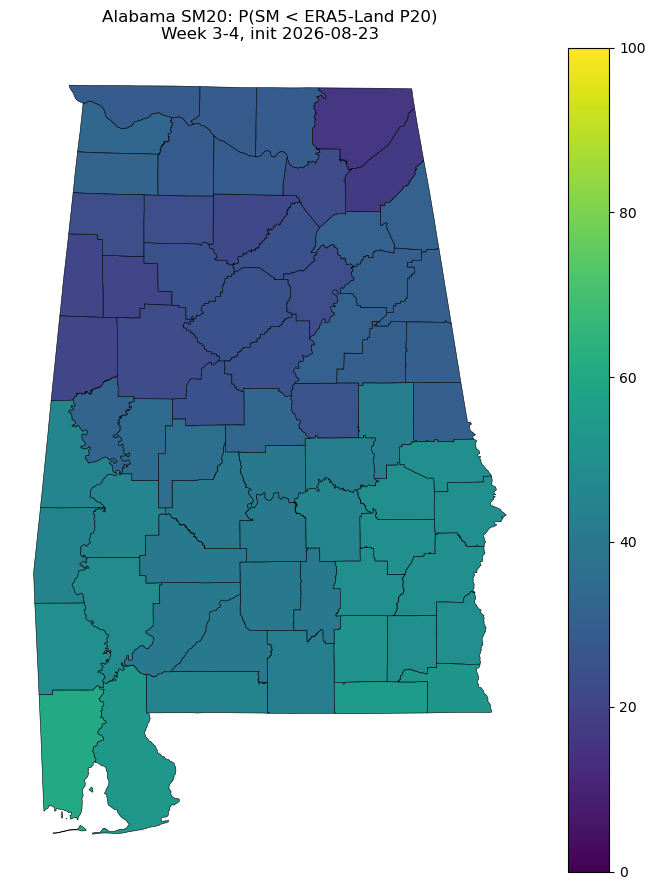

In [16]:

MAP_PERIOD = "Week 3-4"

plot_df = current_summary.loc[
    current_summary.period == MAP_PERIOD
].copy()

plot_gdf = counties.merge(
    plot_df,
    on=[
        "county_fips",
        "county_name"
    ],
    how="left"
)

fig, ax = plt.subplots(
    figsize=(8, 9)
)

plot_gdf.plot(
    column=100.0 * plot_gdf["prob_below_P20"],
    legend=True,
    vmin=0,
    vmax=100,
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    f"Alabama {TARGET.upper()}: "
    f"P(SM < ERA5-Land P20)\n"
    f"{MAP_PERIOD}, init {MODEL_DATE:%Y-%m-%d}"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()



## 14. Map cross-validated calibration improvement

This diagnostic maps:

\[
\Delta RMSE =
RMSE_{raw} - RMSE_{calibrated}
\]

Positive values indicate that calibration reduced RMSE.


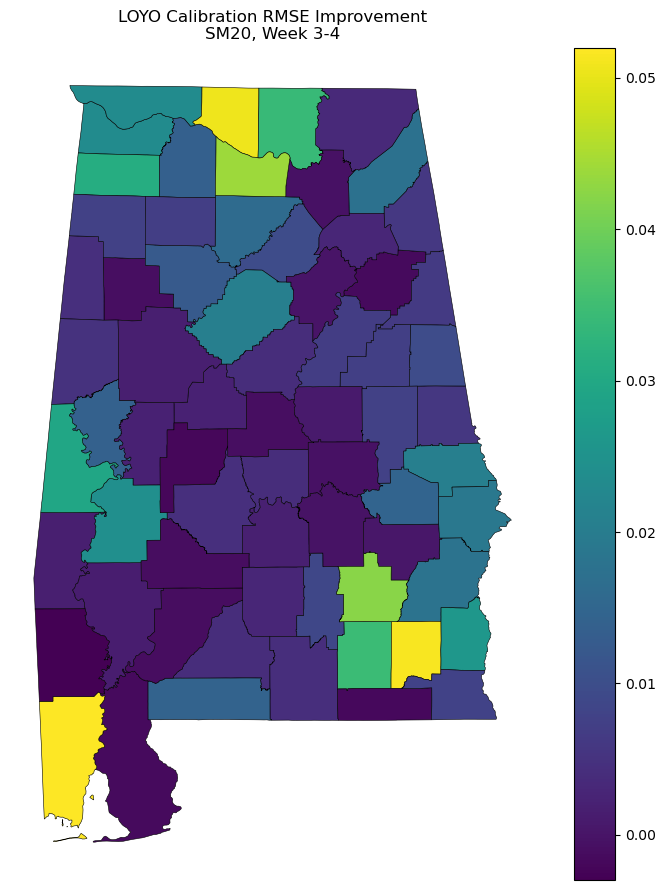

In [17]:

SKILL_PERIOD = "Week 3-4"

skill_df = cv_metrics.loc[
    cv_metrics.period == SKILL_PERIOD
].copy()

skill_df["RMSE_improvement"] = (
    skill_df["raw_RMSE"] -
    skill_df["calibrated_RMSE"]
)

skill_gdf = counties.merge(
    skill_df,
    on=[
        "county_fips",
        "county_name"
    ],
    how="left"
)

fig, ax = plt.subplots(
    figsize=(8, 9)
)

skill_gdf.plot(
    column="RMSE_improvement",
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.4
)

ax.set_title(
    f"LOYO Calibration RMSE Improvement\n"
    f"{TARGET.upper()}, {SKILL_PERIOD}"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()



## 15. Inspect an individual county

Example: Lee County.


In [18]:

COUNTY_TO_VIEW = "Lee"

county_result = current_summary.loc[
    current_summary.county_name ==
    COUNTY_TO_VIEW
].copy()

display(
    county_result[
        [
            "county_name",
            "period",
            "calibrated_ensemble_mean",
            "calibrated_p10",
            "calibrated_median",
            "calibrated_p90",
            "ERA5L_P20_threshold",
            "prob_below_P20",
            "n_native_grid_cells",
            "effective_grid_cells",
            "dominant_cell_fraction",
        ]
    ]
)


,county_name,period,calibrated_ensemble_mean,calibrated_p10,calibrated_median,calibrated_p90,ERA5L_P20_threshold,prob_below_P20,n_native_grid_cells,effective_grid_cells,dominant_cell_fraction
40,Lee,Week 1,0.319321,0.299056,0.319164,0.338235,0.314427,0.376238,1,1.0,1.0
107,Lee,Week 2,0.334776,0.311670,0.338530,0.349542,0.329258,0.376238,1,1.0,1.0
174,Lee,Week 3-4,0.327049,0.296843,0.321964,0.369671,0.319736,0.495050,1,1.0,1.0
241,Lee,Week 5-6,0.327038,0.282213,0.308544,0.370728,0.306673,0.435644,1,1.0,1.0



# How to interpret the county products

For each of Alabama's 67 counties, the pipeline produces:

- raw S2S ensemble mean;
- calibrated ensemble mean;
- calibrated P10/P50/P90;
- ERA5-Land P20 threshold;
- probability that calibrated soil moisture is below P20;
- LOYO bias, RMSE, and correlation;
- native-grid support diagnostics.

## Very important interpretation

A county-specific calibrated value does **not** mean ECMWF is resolving the county physically.

For many Alabama counties:

\[
\text{county size} \ll 1.5^\circ\ \text{S2S grid cell}
\]

so several adjacent counties can inherit essentially the same S2S forecast signal.  
The county differences after calibration primarily reflect county-specific ERA5-Land climatology
and bias mapping.

Therefore, for publication-quality county drought prediction, this experiment should be regarded
as a **statistically localized coarse-resolution S2S forecast**, not a dynamically resolved
county forecast.

## Recommended next scientific upgrades

1. Pool neighboring reforecast initialization dates to enlarge the calibration sample.
2. Verify probabilistic skill with CRPS, Brier score, reliability, and ROC/AUC.
3. Compare `sm20` and `sm100`.
4. Add county-level SCAN/USCRN/in-situ verification where station density permits.
5. Test statistical downscaling using ERA5-Land spatial predictors rather than simple interpolation.
6. Compare county forecasts against a simpler benchmark:
   - persistence;
   - ERA5-Land climatology;
   - uncalibrated ECMWF reforecast climatology.



## 16. Seasonal pooling of initialization dates

Everything above fits one calibration per (county, forecast period) using only the
20 historical reforecasts tied to a single calendar init date (`MODEL_DATE`'s month/day).
That gives each county/period calibration only ~20 training pairs (fewer once members are
collapsed to ensemble stats), which is thin for empirical quantile mapping.

Section 16 pools multiple ECMWF S2S initialization dates that fall in the same
meteorological season into one shared training sample, while still fitting a
separate calibration for every county and every forecast period. The result is the
folder structure:

```
County
 Week1   -> DJF, MAM, JJA, SON
 Week2   -> DJF, MAM, JJA, SON
 Week3-4 -> DJF, MAM, JJA, SON
 Week5-6 -> DJF, MAM, JJA, SON
```
**67 counties x 4 lead periods x 4 seasons = 1,072**; independent empirical-quantile-mapping
fits, each trained on all reforecast members from all pooled init dates x 20 hindcast
years that fall in that season, for that one county and that one lead period.

Seasons used (standard meteorological, not astronomical, seasons):

| Season | Months |
|---|---|
| DJF (winter) | Dec, Jan, Feb |
| MAM (spring) | Mar, Apr, May |
| JJA (summer) | Jun, Jul, Aug |
| SON (autumn) | Sep, Oct, Nov |

In [19]:

# ============================================================
# SEASON DEFINITIONS
# ============================================================

SEASON_MONTHS = {
    "DJF": (12, 1, 2),
    "MAM": (3, 4, 5),
    "JJA": (6, 7, 8),
    "SON": (9, 10, 11),
}

SEASON_OF_MONTH = {
    m: s
    for s, months in SEASON_MONTHS.items()
    for m in months
}


def season_init_dates(season, reference_year, n_dates=6):
    """
    Representative ECMWF S2S initialization dates falling inside a
    meteorological season.

    The on-the-fly S2S reforecast system only has
    data for ODD calendar days of the month (1, 3, 5, ... 31), excluding
    Feb 29.
    """
    months = SEASON_MONTHS[season]

    if season == "DJF":
        start = pd.Timestamp(year=reference_year - 1, month=12, day=1)
        end = pd.Timestamp(year=reference_year, month=2, day=28)
    else:
        start = pd.Timestamp(year=reference_year, month=months[0], day=1)
        end = (
            pd.Timestamp(year=reference_year, month=months[-1], day=1)
            + pd.offsets.MonthEnd(1)
        )

    all_dates = pd.date_range(start, end, freq="D")
    all_dates = all_dates[all_dates.day % 2 == 1]
    all_dates = all_dates[~((all_dates.month == 2) & (all_dates.day == 29))]

    if len(all_dates) <= n_dates:
        return list(all_dates)

    idx = np.linspace(0, len(all_dates) - 1, n_dates).round().astype(int)
    idx = sorted(set(idx))
    return [all_dates[i] for i in idx]

## 17. Pooling + Report


In [20]:
# SECTION 17 -- weekly init dates, Weeks 1-6, fixed pooled LOYO, report
# (report section 3b compares single-date LOYO with seasonal pooling)

import base64
from pathlib import Path

# ---------- 17.0 Settings ----------
PERIODS = {"Week 1": (1, 7), "Week 2": (8, 14), "Week 3-4": (15, 28), "Week 5-6": (29, 42)}
# LEAD_HOURS / LEAD_TIME_FORMATS come from the settings cell (do not override here)
INIT_STEP_DAYS = 7
WINDOW_DAYS = 21            # +/- days around MODEL_DATE used for the current-forecast calibration
SMOKE_TEST_DATES = None     # set to 2 for a quick test; None = all weekly dates
SEASONS = ["DJF", "MAM", "JJA", "SON"]

REPORT_DIR = OUT / "report"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
LIB_ROOT = OUT / f"AL_county_{COUNTY_TAG}_{TARGET}_weekly_library"
LIB_ROOT.mkdir(parents=True, exist_ok=True)


# ---------- 17.1 ERA5-Land target with the correct 72 cm layer-3 weight ----------
def make_era5_target(ds, target=TARGET):
    sv = get_era5_soil_vars(ds)
    sw1, sw2 = ds[sv["layer_1"]], ds[sv["layer_2"]]
    if target == "sm20":
        sm = (7.0 * sw1 + 13.0 * sw2) / 20.0
    elif target == "sm100":
        sw3 = ds[sv["layer_3"]]
        sm = (7.0 * sw1 + 21.0 * sw2 + 72.0 * sw3) / 100.0   # layers: 7, 21, 72 cm
    else:
        raise ValueError("target must be 'sm20' or 'sm100'")
    sm.name = target
    sm.attrs["units"] = "m3 m-3"
    return sm


# ---------- 17.2 Weekly init dates (odd days only, always in the past) ----------
def weekly_init_dates(season, step_days=INIT_STEP_DAYS, lag_days=3, odd_only=True):
    cutoff = pd.Timestamp.today().normalize() - pd.Timedelta(days=lag_days)
    if season == "DJF":
        start, end = pd.Timestamp(2001, 12, 1), pd.Timestamp(2002, 2, 28)
    else:
        m = SEASON_MONTHS[season]
        start = pd.Timestamp(2002, m[0], 1)
        end = pd.Timestamp(2002, m[-1], 1) + pd.offsets.MonthEnd(1)
    out = []
    for t in pd.date_range(start, end, freq=f"{step_days}D"):
        if odd_only and t.day % 2 == 0:          # reforecast requests succeeded only for odd days in the DJF run
            t2 = t + pd.Timedelta(days=1)
            t = t2 if t2.month == t.month else t - pd.Timedelta(days=1)
        # most recent year in which this month/day has already happened
        y = cutoff.year if pd.Timestamp(cutoff.year, t.month, t.day) <= cutoff else cutoff.year - 1
        out.append(pd.Timestamp(y, t.month, t.day))
    return sorted(set(out))


# ---------- 17.3 ERA5-Land county daily series, built ONCE ----------
def build_era5_county_daily(era5_ds, counties, weights, years, target=TARGET, block_years=3):
    soil = get_era5_soil_vars(era5_ds)
    names = [soil["layer_1"], soil["layer_2"]] + ([soil["layer_3"]] if target == "sm100" else [])
    sub_all = era5_ds[names].sel(latitude=slice(29.0, 36.0), longitude=slice(-90.0, -84.0))
    all_times = pd.DatetimeIndex(era5_ds.time.values)

    years = sorted(set(years))
    frames = []
    for i in range(0, len(years), block_years):
        blk = years[i:i + block_years]
        f = OUT / f"ERA5Land_county_daily_{COUNTY_TAG}_{target}_{blk[0]}_{blk[-1]}_sm72.csv"
        if f.exists():
            frames.append(pd.read_csv(f, index_col=0, parse_dates=True))
            continue
        t = pd.date_range(f"{blk[0]}-01-01", f"{blk[-1]}-12-31 18:00", freq="6h").intersection(all_times)
        print(f"ERA5-Land county daily series {blk[0]}-{blk[-1]}: loading {len(t)} timesteps ...")
        block = sub_all.sel(time=t).load()
        sm = make_era5_target(block, target=target)
        c6 = county_area_mean(sm, weights)
        daily = c6.resample(time="1D").mean().transpose("time", "county").to_pandas()
        daily.columns = daily.columns.astype(str)
        daily.to_csv(f)
        frames.append(daily)
    out = pd.concat(frames).sort_index()
    out = out[~out.index.duplicated()]
    return out


def obs_from_daily(daily, init_date, hindcast_years, name_lookup):
    rows = []
    for hy in hindcast_years:
        init = pd.Timestamp(hy, init_date.month, init_date.day)
        for period, (d1, d2) in PERIODS.items():
            # same calendar days the forecast lead window covers (see ERA5_DAY_OFFSET)
            sl = daily.loc[init + pd.Timedelta(days=d1 + ERA5_DAY_OFFSET):
                           init + pd.Timedelta(days=d2 + ERA5_DAY_OFFSET)]
            if len(sl) < (d2 - d1 + 1):
                continue
            m = sl.mean()
            rows.append(pd.DataFrame({
                "county_fips": m.index.astype(str),
                "county_name": [name_lookup[c] for c in m.index],
                "hyear": hy, "period": period, "obs": m.values,
            }))
    return pd.concat(rows, ignore_index=True)


# ---------- 17.4 Pool one season's weekly init dates ----------
def build_weekly_pool(season, dates, counties, daily, s2s_weights, name_lookup, max_workers=4):
    print(f"[{season}] {len(dates)} weekly init dates:", [d.date().isoformat() for d in dates])

    def fetch(d):
        try:
            return d, download_s2s_reforecasts(d, target=TARGET), None
        except Exception as exc:
            return d, None, exc

    downloaded = {}
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        for fut in as_completed([ex.submit(fetch, d) for d in dates]):
            d, files, exc = fut.result()
            downloaded[d] = (files, exc)

    rf_frames, obs_frames, skipped = [], [], []
    for d in dates:
        files, exc = downloaded[d]
        if exc is not None:
            lines = str(exc).splitlines()
            why = next((l for l in lines if "failed with" in l), lines[0])
            skipped.append({"season": season, "init_date": d.date().isoformat(), "reason": why})
            print(f"  ! skipped {d.date()}: {why}")
            continue
        try:
            hyears = list(range(d.year - 20, d.year))
            # DJF: Dec init dates belong to the NEXT calendar year's winter
            sy_shift = 1 if (season == "DJF" and d.month == 12) else 0

            rf_ens = load_s2s_ensemble(files)
            if rf_ens.sizes.get("step", 0) < N_LEAD_DAYS:
                raise RuntimeError(
                    f"GRIB has only {rf_ens.sizes.get('step', 0)} lead step(s); "
                    f"{N_LEAD_DAYS} were requested")
            _, rf_weekly, _, _ = s2s_county_weekly(rf_ens, counties, weights=s2s_weights)
            rf_i = reforecast_to_dataframe(rf_weekly)
            rf_i["county_fips"] = rf_i["county_fips"].astype(str)
            rf_i = rf_i.loc[rf_i.hyear.isin(hyears)].copy()

            obs_i = obs_from_daily(daily, d, hyears, name_lookup)

            for df in (rf_i, obs_i):
                df["season"] = season
                df["init_date"] = d.date().isoformat()
                df["season_year"] = df["hyear"] + sy_shift
            rf_frames.append(rf_i)
            obs_frames.append(obs_i)
        except Exception as exc:
            skipped.append({"season": season, "init_date": d.date().isoformat(),
                            "reason": str(exc).splitlines()[0]})
            print(f"  ! skipped {d.date()}: {exc}")

    if not rf_frames:
        first = skipped[0]["reason"] if skipped else "n/a"
        raise RuntimeError(
            f"[{season}] all {len(dates)} init dates were skipped; first reason: {first}")
    print(f"[{season}] pooled {len(rf_frames)} of {len(dates)} init dates")
    rf_pool = pd.concat(rf_frames, ignore_index=True)
    obs_pool = pd.concat(obs_frames, ignore_index=True)
    return rf_pool, obs_pool, pd.DataFrame(skipped)


# ---------- 17.5 Fixed pooled leave-one-year-out ----------
def loyo_pooled(rf_df, obs_df, year_col="season_year"):
    """Hold out every init date of one season-year; train on all other years.
    Pairs forecasts and observations by (init_date, held-out year)."""
    obs_df = obs_df.drop_duplicates(["county_fips", "period", "init_date", "hyear"])
    rf_g = dict(tuple(rf_df.groupby(["county_fips", "period"], sort=False)))
    obs_g = dict(tuple(obs_df.groupby(["county_fips", "period"], sort=False)))
    rows = []
    for key, rf_p in rf_g.items():
        obs_p = obs_g.get(key)
        if obs_p is None:
            continue
        for ty in sorted(set(rf_p[year_col]) & set(obs_p[year_col])):
            tr_rf, te_rf = rf_p[rf_p[year_col] != ty], rf_p[rf_p[year_col] == ty]
            tr_obs, te_obs = obs_p[obs_p[year_col] != ty], obs_p[obs_p[year_col] == ty]
            if len(tr_obs) < 20 or te_rf.empty or te_obs.empty:
                continue
            cal = empirical_qm(tr_rf["forecast"].values, tr_obs["obs"].values,
                               te_rf["forecast"].values)
            te = (te_rf.assign(cal=cal).groupby("init_date")
                  .agg(raw_mean=("forecast", "mean"), cal_mean=("cal", "mean")))
            te = te.join(te_obs.set_index("init_date")["obs"], how="inner")
            te["clim_obs"] = tr_obs.groupby("init_date")["obs"].mean().reindex(te.index)
            te["clim_raw"] = tr_rf.groupby("init_date")["forecast"].mean().reindex(te.index)
            te = te.reset_index()
            te["county_fips"], te["period"] = key
            te["county_name"] = rf_p["county_name"].iloc[0]
            te["season"] = rf_p["season"].iloc[0]
            te["test_year"] = ty
            rows.append(te)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


def loyo_metrics(pred):
    """Anomalies are taken relative to the per-init-date LOYO climatology, so the
    seasonal cycle inside a pooled season does not inflate correlation."""
    if pred.empty:
        return pd.DataFrame()
    p = pred.dropna(subset=["clim_obs", "clim_raw"]).copy()
    p["obs_a"] = p["obs"] - p["clim_obs"]
    p["cal_a"] = p["cal_mean"] - p["clim_obs"]
    p["raw_a"] = p["raw_mean"] - p["clim_raw"]
    out = []
    for (fips, name, period, season), g in p.groupby(
            ["county_fips", "county_name", "period", "season"], sort=False):
        if len(g) < 10:
            continue
        mse_c = np.mean((g.cal_mean - g.obs) ** 2)
        mse_r = np.mean((g.raw_mean - g.obs) ** 2)
        mse_k = np.mean(g.obs_a ** 2)
        out.append({
            "county_fips": fips, "county_name": name, "period": period, "season": season,
            "n": len(g),
            "raw_bias": (g.raw_mean - g.obs).mean(), "cal_bias": (g.cal_mean - g.obs).mean(),
            "raw_RMSE": np.sqrt(mse_r), "cal_RMSE": np.sqrt(mse_c), "clim_RMSE": np.sqrt(mse_k),
            "raw_ACC": g.raw_a.corr(g.obs_a), "cal_ACC": g.cal_a.corr(g.obs_a),
            "cal_MSESS": 1.0 - mse_c / mse_k,
        })
    return pd.DataFrame(out)


def save_leaf_tree(metrics, root):
    for (county, period, season), g in metrics.groupby(["county_name", "period", "season"]):
        leaf = root / county / period.replace(" ", "") / season
        leaf.mkdir(parents=True, exist_ok=True)
        g.to_csv(leaf / "loyo_metrics.csv", index=False)


# ---------- 17.6 +/- WINDOW_DAYS subset for the current-forecast calibration ----------
def window_subset(rf, obs, target_date, window_days):
    ref = pd.Timestamp(2000, target_date.month, target_date.day).dayofyear

    def near(df):
        uniq = pd.Series(df["init_date"].unique())
        doy = pd.to_datetime(uniq).map(lambda t: pd.Timestamp(2000, t.month, t.day).dayofyear)
        d = (doy.values - ref)
        d = np.minimum(np.abs(d), 366 - np.abs(d))
        keep = set(uniq[d <= window_days])
        return df.loc[df["init_date"].isin(keep)]

    return near(rf), near(obs)


# ---------- 17.7 Figures ----------
def _save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return path


def _map(ax, gdf, col, title, cmap, vmin=None, vmax=None, label=None):
    gdf.plot(column=col, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, edgecolor="black",
             linewidth=0.3, legend=True, legend_kwds={"shrink": 0.6, "label": label},
             missing_kwds={"color": "lightgrey"})
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()


def fig_prob_maps(cs, counties):
    n = len(PERIODS)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 6), squeeze=False)
    for ax, p in zip(axes[0], PERIODS):
        g = counties.merge(cs[cs.period == p], on=["county_fips", "county_name"], how="left")
        g["pct"] = 100 * g["prob_below_P20"]
        _map(ax, g, "pct", p, "YlOrRd", 0, 100, "P(SM < ERA5-Land P20) [%]")
    fig.suptitle(f"Alabama {TARGET}: probability of soil moisture below P20, init {MODEL_DATE:%Y-%m-%d}")
    return _save(fig, "fig1_prob_below_p20.png")


def fig_margin_maps(cs, counties):
    n = len(PERIODS)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 6), squeeze=False)
    cs = cs.assign(margin=cs.calibrated_ensemble_mean - cs.ERA5L_P20_threshold)
    lim = float(np.nanmax(np.abs(cs["margin"]))) or 0.05
    for ax, p in zip(axes[0], PERIODS):
        g = counties.merge(cs[cs.period == p], on=["county_fips", "county_name"], how="left")
        _map(ax, g, "margin", p, "BrBG", -lim, lim, "Calibrated mean - P20 [m3/m3]")
    fig.suptitle("Calibrated ensemble mean relative to the P20 drought threshold (brown = closer to dry)")
    return _save(fig, "fig2_margin_vs_p20.png")


def fig_county_spread(cs, names=("Lee", "Montgomery", "Baldwin", "Madison", "Mobile", "Jefferson")):
    names = [n for n in names if n in set(cs.county_name)]
    if not names:
        return None
    ncol = min(3, len(names))
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.8 * nrow), squeeze=False)
    for ax, n in zip(axes.ravel(), names):
        s = cs[cs.county_name == n].set_index("period").reindex(list(PERIODS))
        x = np.arange(len(s))
        ax.vlines(x, s.calibrated_p10, s.calibrated_p90, lw=8, alpha=0.35, label="P10-P90")
        ax.plot(x, s.calibrated_median, "o", label="median")
        ax.plot(x, s.calibrated_ensemble_mean, "D", label="mean")
        ax.plot(x, s.ERA5L_P20_threshold, "_", ms=36, mew=2, color="red", label="ERA5-Land P20")
        ax.set_xticks(x)
        ax.set_xticklabels(s.index)
        ax.set_title(n)
        ax.set_ylabel(f"{TARGET.upper()} [m3/m3]")
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    axes.ravel()[0].legend(fontsize=8)
    fig.suptitle("Calibrated ensemble spread vs P20 threshold, selected counties")
    fig.tight_layout()
    return _save(fig, "fig3_county_spread.png")


def fig_skill_maps(met, counties, col="cal_MSESS", name="fig4_msess_maps.png",
                   vmin=-1.0, vmax=1.0, label="MSE skill vs climatology",
                   title=None, cmap="RdBu"):
    """Season x period grid of county maps with ONE shared colour bar.
    `title` overrides the default description for the metric shown."""
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    if title is None:
        title = {
            "cal_MSESS": "Leave-one-year-out MSE skill vs climatology "
                         "(blue = smaller errors than assuming normal; 0 = no better; red = worse)",
            "cal_ACC": "Leave-one-year-out anomaly correlation of the calibrated forecast "
                       "(1 = tracks wet/dry departures perfectly; 0 = no relationship)",
            "raw_ACC": "Leave-one-year-out anomaly correlation of the raw forecast "
                       "(1 = tracks wet/dry departures perfectly; 0 = no relationship)",
        }.get(col, f"Leave-one-year-out {label}")

    seasons = [s for s in SEASONS if s in set(met.season)]
    n = len(PERIODS)
    fig, axes = plt.subplots(len(seasons), n, figsize=(4.2 * n, 4.4 * len(seasons)), squeeze=False)
    norm = Normalize(vmin=vmin, vmax=vmax)
    for i, s in enumerate(seasons):
        for j, p in enumerate(PERIODS):
            ax = axes[i, j]
            sub = met[(met.season == s) & (met.period == p)]
            g = counties.merge(sub, on=["county_fips", "county_name"], how="left")
            g.plot(column=col, ax=ax, cmap=cmap, norm=norm, edgecolor="black", linewidth=0.3,
                   missing_kwds={"color": "lightgrey"})
            med = sub[col].median()
            ax.set_title(f"{s} - {p}\nmedian {med:.2f}" if len(sub) else f"{s} - {p}", fontsize=10)
            ax.set_axis_off()

    lo, hi = float(np.nanmin(met[col])), float(np.nanmax(met[col]))
    extend = ("both" if lo < vmin and hi > vmax else "min" if lo < vmin
              else "max" if hi > vmax else "neither")
    fig.subplots_adjust(left=0.02, right=0.88, top=0.93, bottom=0.02, wspace=0.05, hspace=0.18)
    cax = fig.add_axes([0.90, 0.25, 0.015, 0.5])
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, extend=extend)
    cb.set_label(label, fontsize=11)
    fig.suptitle(title, fontsize=13)
    return _save(fig, name)


def fig_skill_summary(met):
    m = met.copy()
    m["raw_absbias"] = m.raw_bias.abs()
    m["cal_absbias"] = m.cal_bias.abs()
    g = m.groupby(["season", "period"]).median(numeric_only=True).reset_index()
    g["season"] = pd.Categorical(g["season"], SEASONS, ordered=True)
    g["period"] = pd.Categorical(g["period"], list(PERIODS), ordered=True)
    g = g.sort_values(["season", "period"])
    labels = (g["season"].astype(str) + "\n" + g["period"].astype(str)).tolist()
    x, w = np.arange(len(g)), 0.38
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    axes[0].bar(x - w / 2, g.raw_ACC, w, label="raw")
    axes[0].bar(x + w / 2, g.cal_ACC, w, label="calibrated")
    axes[0].set_title("Median anomaly correlation (ACC)")
    axes[1].bar(x - w / 2, g.raw_RMSE, w, label="raw")
    axes[1].bar(x + w / 2, g.cal_RMSE, w, label="calibrated")
    axes[1].plot(x, g.clim_RMSE, "k_", ms=22, mew=2, label="climatology")
    axes[1].set_title("Median RMSE [m3/m3]")
    axes[2].bar(x - w / 2, g.raw_absbias, w, label="raw")
    axes[2].bar(x + w / 2, g.cal_absbias, w, label="calibrated")
    axes[2].set_title("Median bias [m3/m3]")
    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=7)
        ax.legend(fontsize=8)
    fig.suptitle("Statewide median of county LOYO metrics")
    fig.tight_layout()
    return _save(fig, "fig5_skill_summary.png")


def fig_grid_support(support, counties):
    g = counties.merge(support, on=["county_fips", "county_name"], how="left")
    fig, axes = plt.subplots(1, 2, figsize=(11, 6))
    _map(axes[0], g, "dominant_cell_fraction", "Share of county from dominant 1.5 deg cell",
         "Blues", 0, 1, "fraction")
    _map(axes[1], g, "n_native_grid_cells", "Native S2S cells overlapping county",
         "viridis", None, None, "cells")
    fig.suptitle("Resolution caveat: how much native S2S information supports each county")
    return _save(fig, "fig6_grid_support.png")


# ---------- 17.7b Single-date LOYO vs seasonally pooled LOYO ----------
def single_vs_pooled_table(single, met, season):
    """
    Per county and period: Section 12 single-date LOYO correlation (raw / calibrated,
    20 years) next to the seasonally pooled LOYO anomaly correlation (raw / calibrated)
    for the season that contains MODEL_DATE.
    """
    s = single.rename(columns={"raw_correlation": "single_raw", "calibrated_correlation": "single_cal",
                               "n_years": "single_n"})
    s["county_fips"] = s["county_fips"].astype(str).str.zfill(5)
    p = met[met.season == season].rename(columns={"raw_ACC": "pooled_raw", "cal_ACC": "pooled_cal",
                                                   "n": "pooled_n"})
    p = p.assign(county_fips=p["county_fips"].astype(str).str.zfill(5))
    t = s[["county_fips", "county_name", "period", "single_n", "single_raw", "single_cal"]].merge(
        p[["county_fips", "period", "pooled_n", "pooled_raw", "pooled_cal"]],
        on=["county_fips", "period"], how="inner")
    t["single_cal_gain"] = t.single_cal - t.single_raw          # what calibration did, single date
    t["pooled_cal_gain"] = t.pooled_cal - t.pooled_raw          # what calibration did, pooled
    t["pooling_change_raw"] = t.pooled_raw - t.single_raw
    t["pooling_change_cal"] = t.pooled_cal - t.single_cal
    return t


def single_vs_pooled_summary(t):
    """Median across counties for each period, plus 95% CI half-widths for typical n."""
    def ci_half(r, n):
        if not np.isfinite(r) or n <= 3:
            return np.nan
        z, se = np.arctanh(np.clip(r, -0.999, 0.999)), 1 / np.sqrt(n - 3)
        lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
        return (hi - lo) / 2
    g = (t.groupby("period")
           .agg(single_n=("single_n", "median"), pooled_n=("pooled_n", "median"),
                single_raw=("single_raw", "median"), single_cal=("single_cal", "median"),
                single_cal_gain=("single_cal_gain", "median"),
                single_pct_improved=("single_cal_gain", lambda d: 100 * (d > 0).mean()),
                pooled_raw=("pooled_raw", "median"), pooled_cal=("pooled_cal", "median"),
                pooled_cal_gain=("pooled_cal_gain", "median"),
                pooled_pct_improved=("pooled_cal_gain", lambda d: 100 * (d > 0).mean()),
                pooling_change_cal=("pooling_change_cal", "median"))
           .reindex(list(PERIODS)).reset_index())
    g["single_ci95"] = [ci_half(r, n) for r, n in zip(g.single_cal, g.single_n)]
    g["pooled_ci95"] = [ci_half(r, n) for r, n in zip(g.pooled_cal, g.pooled_n)]
    return g


def fig_pooling_change_maps(t, counties, vmax=0.3):
    """Three rows of county maps per period:
       1) single-date calibrated correlation, 2) pooled calibrated ACC (same 0-1 scale),
       3) pooled minus single-date (diverging scale)."""
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    rows = [("single_cal", f"Single date ({MODEL_DATE:%d %b}, 20 cases)", "YlGnBu", 0.0, 1.0,
             "Calibrated correlation"),
            ("pooled_cal", "Seasonally pooled (~280 cases)", "YlGnBu", 0.0, 1.0,
             "Calibrated correlation"),
            ("pooling_change_cal", "Pooled minus single date", "RdBu", -vmax, vmax,
             "Change (blue = pooled higher)")]
    n = len(PERIODS)
    fig, axes = plt.subplots(len(rows), n, figsize=(4.2 * n, 4.6 * len(rows)), squeeze=False)
    for i, (col, row_title, cmap, lo, hi, _) in enumerate(rows):
        norm = Normalize(vmin=lo, vmax=hi)
        for j, p in enumerate(PERIODS):
            ax = axes[i, j]
            sub = t[t.period == p][["county_fips", col]]
            g = counties.merge(sub, on="county_fips", how="left")
            g.plot(column=col, ax=ax, cmap=cmap, norm=norm, edgecolor="black", linewidth=0.3,
                   missing_kwds={"color": "lightgrey"})
            ax.set_title(f"{p}\nmedian {sub[col].median():+.2f}" if col == "pooling_change_cal"
                         else f"{p}\nmedian {sub[col].median():.2f}", fontsize=10)
            ax.set_axis_off()
        axes[i, 0].text(-0.08, 0.5, row_title, transform=axes[i, 0].transAxes, rotation=90,
                        ha="center", va="center", fontsize=11, fontweight="bold")

    fig.subplots_adjust(left=0.05, right=0.88, top=0.93, bottom=0.02, wspace=0.05, hspace=0.22)
    # one colour bar for the two correlation rows, one for the difference row
    top = axes[0, -1].get_position(); mid = axes[1, -1].get_position(); bot = axes[2, -1].get_position()
    cax1 = fig.add_axes([0.90, mid.y0, 0.013, top.y1 - mid.y0])
    fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap="YlGnBu"), cax=cax1).set_label(
        "Calibrated correlation (1 = perfect)", fontsize=10)
    cax2 = fig.add_axes([0.90, bot.y0, 0.013, bot.y1 - bot.y0])
    fig.colorbar(ScalarMappable(norm=Normalize(-vmax, vmax), cmap="RdBu"), cax=cax2,
                 extend="both").set_label("Pooled minus single date", fontsize=10)
    fig.suptitle("Calibrated correlation by county: single-date vs seasonally pooled validation",
                 fontsize=13)
    return _save(fig, "fig7_pooling_change_maps.png")


# ---------- 17.7c Reforecast file check: 20 hindcast years in one GRIB ----------
def grib_year_table(path, lat=33.5, lon=273.0):
    """Open one reforecast GRIB and summarize it: file structure, the 20 hindcast
    start dates, and ensemble-mean soil moisture at one grid point for each
    hindcast year and forecast period. lon is on the file's 0-360 scale
    (273.0 = 87.0W)."""
    path = Path(path)
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    var = TARGET if TARGET in ds.data_vars else list(ds.data_vars)[0]
    da = ds[var]
    years = pd.DatetimeIndex(np.atleast_1d(da.time.values))
    lats = ", ".join(f"{v:g}" for v in da.latitude.values)
    lons = ", ".join(f"{v:g} ({v - 360:g})" for v in da.longitude.values)
    summary = {
        "File": path.name,
        "Variable": f"{var} ({da.attrs.get('GRIB_name', '')}, {da.attrs.get('GRIB_units', '')})",
        "Hindcast start dates": f"{da.sizes.get('time', 1)}: {years[0]:%Y-%m-%d} to {years[-1]:%Y-%m-%d}",
        "Ensemble members in file": str(da.sizes.get("number", 1)),
        "Lead days": str(da.sizes.get("step", 1)),
        "Grid latitudes": lats,
        "Grid longitudes (0-360, deg E)": lons,
    }
    pt = da.sel(latitude=lat, longitude=lon) / 1000.0            # kg m-3 -> m3 m-3
    lead_day = (pt.step / pd.Timedelta(days=1)).astype(int)
    mean_dims = [d for d in ("step", "number") if d in pt.dims]
    table = pd.DataFrame({"Hindcast start": years.date})
    for period, (d1, d2) in PERIODS.items():
        sel = pt.where((lead_day >= d1) & (lead_day <= d2), drop=True)
        table[period] = np.atleast_1d(sel.mean(mean_dims).values).round(3)
    ds.close()
    return summary, table


# ---------- 17.8 HTML report ----------
def _b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()


def _img(path, caption):
    if path is None:
        return ""
    return (f'<figure><img src="data:image/png;base64,{_b64(path)}" style="max-width:100%">'
            f"<figcaption>{caption}</figcaption></figure>")


def build_report(cs, met, support, skipped, plan, out_html, single_metrics=None):
    figs = {
        "prob": fig_prob_maps(cs, counties),
        "margin": fig_margin_maps(cs, counties),
        "spread": fig_county_spread(cs),
        "grid": fig_grid_support(support, counties),
    }
    if len(met):
        figs["msess"] = fig_skill_maps(met, counties)
        figs["acc"] = fig_skill_maps(met, counties, col="cal_ACC", name="fig4b_acc_maps.png",
                                     vmin=0, vmax=1, label="Calibrated ACC", cmap="YlGnBu")
        figs["summary"] = fig_skill_summary(met)
        single = single_metrics if single_metrics is not None else globals().get("cv_metrics")
        cmp_season = SEASON_OF_MONTH[pd.Timestamp(MODEL_DATE).month]
        if single is not None and len(single) and cmp_season in set(met.season):
            cmp_t = single_vs_pooled_table(single, met, cmp_season)
            cmp_s = single_vs_pooled_summary(cmp_t)
            cmp_t.to_csv(LIB_ROOT / "single_date_vs_pooled_by_county.csv", index=False)
            cmp_s.to_csv(LIB_ROOT / "single_date_vs_pooled_summary.csv", index=False)
            figs["cmp_maps"] = fig_pooling_change_maps(cmp_t, counties)

    bul = []
    for p in PERIODS:
        s = cs[cs.period == p]
        if len(s):
            bul.append(
                f"<li><b>{p}</b>: statewide mean P(SM&lt;P20) = {100 * s.prob_below_P20.mean():.0f}%; "
                f"{int((s.prob_below_P20 >= 0.5).sum())} of {len(s)} counties have a probability of 50% or more; "
                f"mean calibrated ensemble is {(s.calibrated_ensemble_mean - s.ERA5L_P20_threshold).mean():+.3f} "
                f"m3/m3 relative to P20.</li>")
    if len(met):
        for p in PERIODS:
            m = met[met.period == p]
            if len(m):
                bul.append(
                    f"<li><b>Validation, {p}</b>: median calibrated ACC {m.cal_ACC.median():.2f} "
                    f"(raw {m.raw_ACC.median():.2f}); median MSE skill vs climatology "
                    f"{m.cal_MSESS.median():+.2f}; calibration lowers RMSE in "
                    f"{100 * (m.cal_RMSE < m.raw_RMSE).mean():.0f}% of county-season fits.</li>")
    n_dom = int((support.dominant_cell_fraction >= 0.8).sum())
    bul.append(f"<li><b>Resolution</b>: {n_dom} of {len(support)} counties draw at least 80% of their "
               f"forecast from a single 1.5 deg S2S cell, so neighbouring counties share most of the "
               f"forecast signal.</li>")

    css = ("body{font-family:Arial,sans-serif;max-width:1100px;margin:30px auto;line-height:1.45}"
           "table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #bbb;padding:3px 7px}"
           "figure{margin:18px 0}figcaption{font-size:12px;color:#555}")
    h = [f"<html><head><meta charset='utf-8'><style>{css}</style></head><body>",
         f"<h1>Alabama county ECMWF S2S {TARGET} calibrated soil-moisture outlook</h1>",
         f"<p>Forecast init: <b>{MODEL_DATE:%Y-%m-%d}</b>. Periods: {', '.join(PERIODS)}. "
         f"Reference: ERA5-Land county means; 20-year ECMWF reforecasts; weekly init dates pooled by season.</p>",
         "<h2>1. Key findings</h2><ul>" + "".join(bul) + "</ul>",
         "<h2>2. Current forecast</h2>",
         _img(figs["prob"], "Probability that calibrated soil moisture is below the county ERA5-Land P20."),
         _img(figs["margin"], "Calibrated ensemble mean minus P20 threshold."),
         _img(figs["spread"], "Calibrated P10-P90 range, median and mean against the P20 threshold."),
         "<h3>Counties with highest P(SM&lt;P20)</h3>"]
    for p in PERIODS:
        t = cs[cs.period == p].sort_values("prob_below_P20", ascending=False).head(8)[
            ["county_name", "prob_below_P20", "calibrated_ensemble_mean", "ERA5L_P20_threshold"]]
        h.append(f"<h4>{p}</h4>" + t.to_html(index=False, float_format=lambda v: f"{v:.3f}"))
    if len(met):
        h += ["<h2>3. Leave-one-year-out validation</h2>",
              _img(figs["summary"], "Statewide medians of county metrics by season and period."),
              _img(figs["msess"], "MSE skill score vs per-init-date climatology (positive = better)."),
              _img(figs["acc"], "Anomaly correlation of the calibrated ensemble mean.")]
        if "cmp_maps" in figs:
            h += [f"<h2>3b. Single-date vs seasonally pooled validation</h2>",
                  f"<p>Calibrated correlation from the single-date test ({MODEL_DATE:%d %B}, 20 years) compared "
                  f"with the seasonally pooled test ({cmp_season}, about {int(cmp_s.pooled_n.median())} cases per "
                  "county). With a single date, calibration lowers correlation by "
                  + ", ".join(f"{r.period} {r.single_cal_gain:+.2f}" for r in cmp_s.itertuples())
                  + "; with pooling the change is about zero ("
                  + ", ".join(f"{r.period} {r.pooled_cal_gain:+.3f}" for r in cmp_s.itertuples())
                  + "). Blue counties gain from pooling. Pooled scores are also far more precise "
                  f"(&plusmn;{cmp_s.pooled_ci95.median():.2f} vs &plusmn;{cmp_s.single_ci95.median():.2f}), "
                  "so they are the values to report.</p>",
                  _img(figs["cmp_maps"], "Calibrated correlation by county. Top: single-date test; "
                                         "middle: seasonally pooled test (same colour scale); "
                                         "bottom: pooled minus single date (blue = higher with pooling).")]
        else:
            h += ["<h2>3b. Single-date vs seasonally pooled validation</h2>",
                  "<p>Not shown: Section 12 single-date metrics (<code>cv_metrics</code>) were not available, "
                  "or the forecast date's season is not in the pooled results.</p>"]
    h += ["<h2>4. Resolution caveat</h2>",
          _img(figs["grid"], "Native S2S grid support per county."),
          "<p>Calibration is county-specific, but the dynamical signal comes from the ~1.5 deg S2S grid. "
          "County differences mostly reflect county-specific ERA5-Land climatology.</p>",
          "<h2>5. Setup</h2>"]
    for s in SEASONS:
        if s in plan:
            h.append(f"<p><b>{s}</b> ({len(plan[s])} weekly init dates): "
                     + ", ".join(d.date().isoformat() for d in plan[s]) + "</p>")
    if len(skipped):
        h.append("<h3>Skipped init dates</h3>" + skipped.to_html(index=False))

    # --- Reforecast file check (20 hindcast years) ---
    rf_file = RAW / f"ecmwf_s2s_rf_{TARGET}_{pd.Timestamp(MODEL_DATE):%Y_%m_%d}_pf.grib"
    if not rf_file.exists():
        rf_candidates = sorted(RAW.glob(f"ecmwf_s2s_rf_{TARGET}_*_pf.grib"))
        rf_file = rf_candidates[0] if rf_candidates else None
    if rf_file is not None:
        try:
            g_lat, g_lon = 33.5, 273.0
            g_sum, g_tab = grib_year_table(rf_file, g_lat, g_lon)
            g_tab.to_csv(LIB_ROOT / f"grib_year_table_{rf_file.stem}.csv", index=False)
            h += ["<h3>Reforecast data check: 20 hindcast years in one file</h3>",
                  "<p>Contents of one downloaded ECMWF reforecast file (perturbed members), read "
                  "directly from the GRIB. Each row of the second table is a separate model run "
                  "started on the same calendar date in a different past year; values are the "
                  f"ensemble-mean {TARGET} (m3/m3) at the grid point {g_lat}N {360 - g_lon:.1f}W "
                  "(central Alabama: Jefferson, Walker, Shelby, Bibb, Blount and neighbouring "
                  "counties), averaged over each forecast period.</p>",
                  pd.DataFrame(list(g_sum.items()), columns=["Item", "Value"]).to_html(index=False),
                  "<br>",
                  g_tab.to_html(index=False, float_format=lambda v: f"{v:.3f}")]
        except Exception as exc:
            h.append(f"<p>Reforecast data check skipped: {exc}</p>")

    h += ["<h2>6. Method notes and limitations</h2><ul>"
          "<li>Empirical quantile mapping per county, period and pool; ERA5-Land is treated as truth.</li>"
          f"<li>{TARGET} from ERA5-Land layers uses "
          + ("7/21/72 cm" if TARGET == "sm100" else "7/13 cm") + " layer weights.</li>"
          f"<li>The current forecast is calibrated with init dates within +/-{WINDOW_DAYS} days of the "
          "forecast date, so the P20 threshold respects the time of year.</li>"
          "<li>Validation holds out whole season-years. Init dates a week apart are strongly correlated, "
          "so the effective sample size is smaller than the number of rows.</li>"
          "<li>Skill is measured against ERA5-Land, not in-situ observations. Probabilities are not "
          "verified with Brier score or reliability diagrams here.</li>"
          "</ul></body></html>"]
    Path(out_html).write_text("\n".join(h), encoding="utf-8")
    print("Report written:", out_html)


# ============================================================
# 17.9 DRIVER
# ============================================================
name_lookup = dict(zip(counties["county_fips"].astype(str), counties["county_name"]))
CURRENT_SEASON = SEASON_OF_MONTH[pd.Timestamp(MODEL_DATE).month]

plan = {s: weekly_init_dates(s) for s in SEASONS}
if SMOKE_TEST_DATES:
    plan = {s: d[:SMOKE_TEST_DATES] for s, d in plan.items()}
for s in SEASONS:
    print(s, len(plan[s]), "init dates")

all_dates = [d for v in plan.values() for d in v]
years_needed = range(min(d.year for d in all_dates) - 20, max(d.year for d in all_dates) + 1)

# One pass over ERA5-Land instead of one per init date
era5_daily = build_era5_county_daily(era5, counties, era5_weights, years_needed)

pools_rf, pools_obs, all_pred, all_met, all_skipped = {}, {}, [], [], []
for season in SEASONS:
    print(f"\n=== {season} ===")
    rf_pool, obs_pool, skipped = build_weekly_pool(
        season, plan[season], counties, era5_daily, s2s_weights, name_lookup)
    rf_pool.to_csv(LIB_ROOT / f"pooled_reforecasts_{season}.csv", index=False)
    obs_pool.to_csv(LIB_ROOT / f"pooled_obs_{season}.csv", index=False)
    pools_rf[season], pools_obs[season] = rf_pool, obs_pool
    all_skipped.append(skipped)

    pred = loyo_pooled(rf_pool, obs_pool)
    met = loyo_metrics(pred)
    print(f"{season}: LOYO prediction rows={len(pred)}, metric rows={len(met)}")
    if len(met):
        save_leaf_tree(met, LIB_ROOT)
    all_pred.append(pred)
    all_met.append(met)

cv_pred_all = pd.concat(all_pred, ignore_index=True)
cv_met_all = pd.concat(all_met, ignore_index=True)
skipped_all = pd.concat(all_skipped, ignore_index=True) if all_skipped else pd.DataFrame()
cv_pred_all.to_csv(LIB_ROOT / "ALL_LOYO_predictions.csv", index=False)
cv_met_all.to_csv(LIB_ROOT / "ALL_LOYO_metrics.csv", index=False)
skipped_all.to_csv(LIB_ROOT / "skipped_init_dates.csv", index=False)
assert len(cv_met_all) > 0, "LOYO metrics are empty -- inspect pools before continuing"

# Current forecast: calibrate with +/- WINDOW_DAYS init dates (can cross season boundaries)
rf_all = pd.concat(pools_rf.values(), ignore_index=True)
obs_all = pd.concat(pools_obs.values(), ignore_index=True)
rf_w, obs_w = window_subset(rf_all, obs_all, pd.Timestamp(MODEL_DATE), WINDOW_DAYS)
rt_df_p = rt_df[rt_df["period"].isin(PERIODS)].copy()
current_summary_w, current_members_w = calibrate_current_by_county(rf_w, obs_w, rt_df_p, s2s_support)
current_summary_w.to_csv(LIB_ROOT / f"forecast_summary_{MODEL_DATE:%Y_%m_%d}_window{WINDOW_DAYS}d.csv", index=False)
current_members_w.to_csv(LIB_ROOT / f"calibrated_members_{MODEL_DATE:%Y_%m_%d}_window{WINDOW_DAYS}d.csv", index=False)

build_report(current_summary_w, cv_met_all, s2s_support, skipped_all, plan,
             REPORT_DIR / f"AL_{TARGET}_S2S_report_{MODEL_DATE:%Y_%m_%d}.html",
             single_metrics=cv_metrics)   # Section 12 single-date LOYO metrics

DJF 13 init dates
MAM 14 init dates
JJA 14 init dates
SON 13 init dates
ERA5-Land county daily series 2005-2007: loading 4380 timesteps ...
ERA5-Land county daily series 2008-2010: loading 4384 timesteps ...
ERA5-Land county daily series 2011-2013: loading 4384 timesteps ...
ERA5-Land county daily series 2014-2016: loading 4384 timesteps ...
ERA5-Land county daily series 2017-2019: loading 4380 timesteps ...
ERA5-Land county daily series 2020-2022: loading 4384 timesteps ...
ERA5-Land county daily series 2023-2025: loading 4384 timesteps ...
ERA5-Land county daily series 2026-2026: loading 1100 timesteps ...

=== DJF ===
[DJF] 13 weekly init dates: ['2025-12-01', '2025-12-09', '2025-12-15', '2025-12-23', '2025-12-29', '2026-01-05', '2026-01-13', '2026-01-19', '2026-01-27', '2026-02-03', '2026-02-09', '2026-02-17', '2026-02-23']


Recovering from HTTP error [502 Bad Gateway], attempt 1 of 500
Retrying in 120 seconds
2026-10-07 11:44:39,162 INFO Request ID is b1f52a50-2070-47db-bb59-0cef2479334b
2026-10-07 11:44:39,413 INFO status has been updated to successful
2026-10-07 11:44:40,241 INFO Request ID is 667a05be-77fa-418f-bacc-b5bfdaf5dbc3
2026-10-07 11:44:40,404 INFO status has been updated to successful
2026-10-07 11:44:41,534 INFO Request ID is 9ce66cd0-8ad5-4e0e-b772-cf4f1aa14ce5


441bb9b0bbe102ccdd5add2123dda983.grib:   0%|          | 0.00/204k [00:00<?, ?B/s]

1d989c6fd47182c80b2af597b0baea2a.grib:   0%|          | 0.00/204k [00:00<?, ?B/s]

2026-10-07 11:44:41,701 INFO status has been updated to successful


...

2026-10-07 12:14:24,677 INFO Request ID is 3c9b32f4-3b70-4e8b-9a9a-3c9682124f28
2026-10-07 12:14:24,992 INFO status has been updated to successful


eadbe560c3ba4bca1a5039bbb9152c07.grib:   0%|          | 0.00/204k [00:00<?, ?B/s]

2026-10-07 12:14:33,139 INFO Request ID is 2d80dc15-b67e-4147-999b-06a70155df24
2026-10-07 12:14:33,292 INFO status has been updated to successful


ddf102d87915cb278ceeab24ebaa4a6.grib:   0%|          | 0.00/1.99M [00:00<?, ?B/s]

[SON] pooled 13 of 13 init dates
SON: LOYO prediction rows=69680, metric rows=268
Report written: alabama_county_s2s_experiment_sm20/output/report/AL_sm20_S2S_report_20260823.html
